# Reversible GPT — the whole experiment in one notebook (v3)

> **Executed run.** This notebook was run top to bottom on a Colab Tesla T4: 22 training runs, 4.7 h of training, no errors. The full write-up with every result, figure and finding is in [`README.md`](README.md); raw results are in [`results/`](results/) and figures in [`assets/`](assets/).
>
> **After the run**, four wording bugs in the reporting code (cell [10]) were fixed and the plots made clearer. The three output-only cells that depend on that code (Step 5 selection note, Step 8 plots, Step 8 report) were re-executed against the saved results; no model was retrained. Every training log and every table is the original Colab output. Details: the note at the end of Step 8.

A ~21M-parameter GPT on a 50M-token FineWeb-Edu budget, with and without reversible residual blocks.

| Run | What |
|---|---|
| 1 | Baseline at a fixed micro-batch `B_BASE` |
| 2 | RevNet, midpoint and momentum, **each on the full budget** at `B_BASE`; the best that passes a numerics gate is selected |
| 3 | Selected variant at its max micro-batch: LR sweep + baseline control at the same effective batch |

Supporting: 3 seeds for runs 1 and 2, an autograd control for **every** variant (same architecture, ordinary backward), a max-batch vs max-batch table with activation checkpointing, memory probes with and without a chunked loss.

**How to run:** Runtime → Change runtime type → **T4 GPU**, then Runtime → **Run all**. `BUDGET="full"` ≈ 5 h on a T4 (use `USE_DRIVE=True`), `"core"` ≈ 2.3 h. Every training step skips runs whose result file already exists, so with `USE_DRIVE=True` Run all after a disconnect resumes where it stopped.

**Layout:** cells **[0]–[10]** define all the code. **Steps 1–9** run the experiment and write the README.

**What changed from v1** (first GPU run): momentum normalised (α = 1−γ); no short pilots, every variant trains on the full schedule; gradients audited against an fp32 ground truth throughout training; run 3 gets an LR sweep and a same-batch control; max-batch comparison includes the baseline's own max and checkpointing; seeds. The README's section 3 lists the evidence for each change.

**What changed from v2:** tokens/s no longer inflated by evals between log points; peak memory is the training peak only (the fp32 audit is measured apart); MFU looks up the GPU by whole name; the gradient audit uses 16 windows, judges the engine against SGD gradient noise and takes the 90th percentile; autograd controls for all variants; run 3 and its baseline control share an LR grid that starts at 3e-4 and extends itself past an edge optimum; the step-matched health check is gone; mean ± SE everywhere; a hypothesis scorecard and an answer-to-the-brief paragraph are generated. Results go to `results_v3/`, so v2 files are never reused.

In [1]:
# ---- Settings: the only cell you may need to edit --------------------------------
USE_DRIVE = False        # True: data/results in MyDrive/rev-gpt -> survives disconnects, Run all resumes
BUDGET = "full"          # "full" (~5 h on T4) or "core" (~2.3 h): see the plan printed below
TOTAL_TOKENS = 50_000_000
GAMMA_SWEEP = False      # True: also train momentum with gamma 0.5 and 0.7 (+2 runs, ablation only)

SEEDS = [1337, 1338, 1339] if BUDGET == "full" else [1337]
# v2's sweep (1e-3, 2e-3, 3e-3) found loss RISING with LR, so its best value sat on the grid edge. v3 starts lower
# and extends the grid automatically (x/÷1.4, up to 2 extra points) whenever a sweep's best LR is on an edge.
RUN3_LRS = [3e-4, 5e-4, 7e-4, 1e-3] if BUDGET == "full" else [1e-3]
LR_EXTEND = 2 if BUDGET == "full" else 0
VARIANTS = ["revnet", "midpoint", "momentum"]
CE_CHUNK = 4096          # tokens per chunk for the chunked-loss memory probes

import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"  # before torch import: less fragmentation
if USE_DRIVE:
    # "credential propagation was unsuccessful": re-run, sign in with the SAME account as Colab and
    # tick every permission box -- or set USE_DRIVE = False.
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = "/content/drive/MyDrive/rev-gpt"
else:
    ROOT = "/content/rev-gpt" if os.path.isdir("/content") else os.path.abspath("rev-gpt")
# results_v3: never mix with v2 result files (run_or_load would silently reuse runs made with the old trainer)
DATA_DIR, RES_DIR, ASSETS = f"{ROOT}/data", f"{ROOT}/results_v3", f"{ROOT}/assets"
for d in (DATA_DIR, RES_DIR, ASSETS):
    os.makedirs(d, exist_ok=True)

n_runs = (1 + 2 * len(VARIANTS) + 2 * (len(SEEDS) - 1) + 2 * len(RUN3_LRS) + (1 if BUDGET == "full" else 0)
          + (2 if GAMMA_SWEEP else 0))
print(f"working folder: {ROOT}\nbudget '{BUDGET}': {n_runs} training runs of {TOTAL_TOKENS/1e6:.0f}M tokens "
      f"(~{n_runs*14/60:.1f} h of training on a T4, + up to {2*LR_EXTEND} LR-extension runs) + data and probes")
if BUDGET == "full" and not USE_DRIVE:
    print("WARNING: a long run without Drive loses everything on disconnect. Consider USE_DRIVE = True.")

working folder: /content/rev-gpt
budget 'full': 20 training runs of 50M tokens (~4.7 h of training on a T4, + up to 4 LR-extension runs) + data and probes


In [2]:
!pip -q install datasets tokenizers tabulate

## [0] Imports and GPU check

In [3]:
import gc
import json
import math
import os
import re
import time
from dataclasses import asdict, dataclass, field
from typing import Optional

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.checkpoint import checkpoint
import glob, re, shutil
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, Image, display

assert torch.cuda.is_available(), "No GPU: Runtime -> Change runtime type -> T4 GPU, then Run all again"
print(torch.__version__, "|", torch.cuda.get_device_name(), "|",
      f"{torch.cuda.get_device_properties(0).total_memory/2**30:.1f} GB")

2.11.0+cu130 | Tesla T4 | 14.6 GB


## [1] Configs
`ModelConfig` (architecture, incl. `rev_impl` for the autograd control and `ce_chunk_tokens` for the chunked loss) and `TrainConfig` (run). Momentum's `alpha` defaults to 1−γ.

In [4]:
# ============================================================================
# [1] Configs
# ============================================================================

ARCHS = ("baseline", "revnet", "midpoint", "momentum")


@dataclass
class ModelConfig:
    vocab_size: int = 8192
    block_size: int = 512          # context length T
    n_layer: int = 10
    n_head: int = 6
    d_model: int = 384
    mlp_ratio: int = 4
    arch: str = "baseline"         # one of ARCHS
    alpha: Optional[float] = None  # coefficient on the residual function; None -> 1.0 (revnet, midpoint)
                                   # or 1 - gamma (momentum, Sander et al. 2021 normalisation)
    gamma: float = 0.9             # momentum coefficient (momentum scheme only)
    grad_checkpoint: bool = False  # baseline only: activation checkpointing (comparison point)
    rev_impl: str = "engine"       # reversible archs: "engine" (memory-saving backward) or
                                   # "autograd" (same maths, ordinary backward; the engine-error control)
    ce_chunk_tokens: int = 0       # >0: LM head + loss in checkpointed chunks of this many tokens, so the
                                   # B*T*V logits tensor never exists (memory independent of batch size)

    def __post_init__(self):
        assert self.arch in ARCHS, f"arch must be one of {ARCHS}"
        assert self.d_model % self.n_head == 0
        assert not (self.grad_checkpoint and self.arch != "baseline"), "checkpointing is a baseline option"
        assert self.rev_impl in ("engine", "autograd")
        assert self.ce_chunk_tokens >= 0

    def resolved_alpha(self):
        if self.alpha is not None:
            return self.alpha
        return 1.0 - self.gamma if self.arch == "momentum" else 1.0


@dataclass
class TrainConfig:
    run_name: str = "run"
    data_dir: str = "data"
    out_dir: str = "results"
    micro_batch: int = 32
    grad_accum: int = 1
    total_tokens: int = 50_000_000  # steps = ceil(total_tokens / tokens_per_step): at least this many tokens
    lr: float = 1e-3
    min_lr_frac: float = 0.1
    warmup_frac: float = 0.05
    min_warmup_steps: int = 25
    weight_decay: float = 0.1
    beta1: float = 0.9
    beta2: float = 0.95
    grad_clip: float = 1.0
    log_every: int = 25            # optimizer steps
    eval_every_tokens: int = 5_000_000
    eval_windows: int = 256        # periodic eval: first 256 val windows (~131k tokens); final eval uses all
    audit_windows: int = 16        # gradient audit batch (8,192 tokens), plus a second disjoint batch of the
                                   # same size for the gradient-noise reference; computed in chunks of 4
    throughput_skip_frac: float = 0.05  # ignore the first 5% of steps when averaging tokens/s
    seed: int = 1337
    dtype: str = "auto"            # auto | bf16 | fp16 | fp32
    save_checkpoint: bool = True
    extra: dict = field(default_factory=dict)  # free-form notes copied into the results JSON

## [2] Building blocks
Sublayers return only their *update*, cast to fp32, so the residual stream stays fp32.

In [5]:
# ============================================================================
# [2] Building blocks
# ============================================================================

class CausalSelfAttention(nn.Module):
    def __init__(self, cfg: ModelConfig):
        super().__init__()
        self.n_head = cfg.n_head
        self.qkv = nn.Linear(cfg.d_model, 3 * cfg.d_model, bias=False)
        self.proj = nn.Linear(cfg.d_model, cfg.d_model, bias=False)
        self.proj.is_residual_proj = True

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=2)
        q, k, v = (t.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) for t in (q, k, v))
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        return self.proj(y.transpose(1, 2).contiguous().view(B, T, C))


class MLP(nn.Module):
    def __init__(self, cfg: ModelConfig):
        super().__init__()
        self.fc = nn.Linear(cfg.d_model, cfg.mlp_ratio * cfg.d_model, bias=False)
        self.proj = nn.Linear(cfg.mlp_ratio * cfg.d_model, cfg.d_model, bias=False)
        self.proj.is_residual_proj = True

    def forward(self, x):
        return self.proj(F.gelu(self.fc(x), approximate="tanh"))


class AttnSub(nn.Module):
    """F(x) = Attn(LN(x)). Returns the residual *update*, in fp32."""
    def __init__(self, cfg):
        super().__init__()
        self.ln = nn.LayerNorm(cfg.d_model, bias=False)
        self.attn = CausalSelfAttention(cfg)

    def forward(self, x):
        return self.attn(self.ln(x)).float()


class MLPSub(nn.Module):
    """G(x) = MLP(LN(x)). Returns the residual *update*, in fp32."""
    def __init__(self, cfg):
        super().__init__()
        self.ln = nn.LayerNorm(cfg.d_model, bias=False)
        self.mlp = MLP(cfg)

    def forward(self, x):
        return self.mlp(self.ln(x)).float()


class Block(nn.Module):
    """Holds the two sublayers. The *same parameters* are used by every architecture;
    only the way the residual stream is wired around them changes."""
    def __init__(self, cfg):
        super().__init__()
        self.f = AttnSub(cfg)
        self.g = MLPSub(cfg)

    def delta(self, x):
        """Full-block residual function: Block(x) - x for a standard pre-norm block."""
        a = self.f(x)
        return a + self.g(x + a)

    def forward(self, x):  # standard (non-reversible) pre-norm block
        x = x + self.f(x)
        return x + self.g(x)

## [3] Reversible schemes
RevNet (symplectic Euler), leapfrog midpoint, momentum: `step`, exact `inverse`, fused `backward_step`.

In [6]:
# ============================================================================
# [3] Reversible schemes
#
# Each scheme carries a *state tuple* through the stack and implements:
#   init_state(x)                 embedding -> initial state
#   step(blk, s)                  forward one layer
#   inverse(blk, s)               exact algebraic inverse of step (no grad; used by tests)
#   backward_step(blk, s, ds)     reconstruct the previous state AND push gradients through
#                                 the layer, evaluating each sublayer exactly ONCE
#   readout(s)                    state -> tensor for the final LayerNorm
# The residual stream is kept in fp32: reconstruction subtracts what was added,
# and in fp16 the rounding error of that subtraction would swamp the signal.
# ============================================================================

class RevNetScheme:
    """Additive coupling (Gomez et al. 2017; Reformer 2020) = symplectic Euler on a split state.
        y1 = x1 + a*F(x2)        (F = attention sublayer)
        y2 = x2 + a*G(y1)        (G = MLP sublayer)
    Inverse: x2 = y2 - a*G(y1);  x1 = y1 - a*F(x2)."""
    name = "revnet"

    def __init__(self, alpha=1.0):
        self.a = alpha

    def init_state(self, x):
        return (x, x)

    def step(self, blk, s):
        x1, x2 = s
        y1 = x1 + self.a * blk.f(x2)
        y2 = x2 + self.a * blk.g(y1)
        return (y1, y2)

    @torch.no_grad()
    def inverse(self, blk, s):
        y1, y2 = s
        x2 = y2 - self.a * blk.g(y1)
        x1 = y1 - self.a * blk.f(x2)
        return (x1, x2)

    def backward_step(self, blk, s, ds):
        y1, y2 = s
        dy1, dy2 = ds
        # (1) G-branch: recompute G(y1) with grad, push dy2 through it.
        with torch.enable_grad():
            y1_ = y1.detach().requires_grad_(True)
            g = self.a * blk.g(y1_)
            torch.autograd.backward(g, dy2)          # accumulates G's param grads into .grad
        with torch.no_grad():
            x2 = y2 - g.detach()                      # reconstruction reuses the same G evaluation
            dy1_total = dy1 + y1_.grad                # y1 influences the loss directly AND via y2
        # (2) F-branch: recompute F(x2) with grad, push dy1_total through it.
        with torch.enable_grad():
            x2_ = x2.detach().requires_grad_(True)
            f = self.a * blk.f(x2_)
            torch.autograd.backward(f, dy1_total)
        with torch.no_grad():
            x1 = y1 - f.detach()
            dx2 = dy2 + x2_.grad
        return (x1, x2), (dy1_total, dx2)

    def readout(self, s):
        return 0.5 * (s[0] + s[1])


class MidpointScheme:
    """Leapfrog / explicit-midpoint two-step scheme (Chang et al. 2018):
        x_{n+1} = x_{n-1} + a*D_n(x_n),    a = 2h,   D_n = full block residual (Block.delta)
    State = (x_{n-1}, x_n).  Inverse: x_{n-1} = x_{n+1} - a*D_n(x_n).
    Note: this is a RevNet-style coupling in which every *full block* is a coupling function."""
    name = "midpoint"

    def __init__(self, alpha=1.0):
        self.a = alpha

    def init_state(self, x):
        return (x, x)                                 # (x_{-1}, x_0)

    def step(self, blk, s):
        prev, cur = s
        return (cur, prev + self.a * blk.delta(cur))

    @torch.no_grad()
    def inverse(self, blk, s):
        cur, nxt = s
        return (nxt - self.a * blk.delta(cur), cur)

    def backward_step(self, blk, s, ds):
        cur, nxt = s
        dcur, dnxt = ds
        with torch.enable_grad():
            cur_ = cur.detach().requires_grad_(True)
            d = self.a * blk.delta(cur_)
            torch.autograd.backward(d, dnxt)
        with torch.no_grad():
            prev = nxt - d.detach()
            dprev = dnxt                              # nxt = prev + ...  => d nxt/d prev = I
            dcur_total = dcur + cur_.grad
        return (prev, cur), (dprev, dcur_total)

    def readout(self, s):
        return 0.5 * (s[0] + s[1])


class MomentumScheme:
    """Momentum residual (Sander et al. 2021):
        v_{n+1} = g*v_n + a*D_n(x_n);   x_{n+1} = x_n + v_{n+1}
    Inverse: x_n = x_{n+1} - v_{n+1};   v_n = (v_{n+1} - a*D_n(x_n)) / g.
    Default a = 1 - g keeps v a weighted *average* of block updates. With a = 1 (v1 of this repo)
    v accumulates up to 1/(1-g) = 10x a block update, early layers are over-weighted, and the
    inverse becomes badly conditioned. Division by g also amplifies float error by 1/g per layer."""
    name = "momentum"

    def __init__(self, alpha=1.0, gamma=0.9):
        assert gamma > 0
        self.a, self.g = alpha, gamma

    def init_state(self, x):
        return (x, torch.zeros_like(x))

    def step(self, blk, s):
        x, v = s
        v = self.g * v + self.a * blk.delta(x)
        return (x + v, v)

    @torch.no_grad()
    def inverse(self, blk, s):
        xn, vn = s
        x = xn - vn
        return (x, (vn - self.a * blk.delta(x)) / self.g)

    def backward_step(self, blk, s, ds):
        xn, vn = s
        dxn, dvn = ds
        with torch.no_grad():
            x = xn - vn                               # no network call needed for x
            dv_total = dvn + dxn                      # v_{n+1} reaches the loss directly and via x_{n+1}
        with torch.enable_grad():
            x_ = x.detach().requires_grad_(True)
            d = self.a * blk.delta(x_)
            torch.autograd.backward(d, dv_total)
        with torch.no_grad():
            v = (vn - d.detach()) / self.g
            dx = dxn + x_.grad
            dv = self.g * dv_total
        return (x, v), (dx, dv)

    def readout(self, s):
        return s[0]


def make_scheme(cfg: ModelConfig):
    a = cfg.resolved_alpha()
    if cfg.arch == "revnet":
        return RevNetScheme(a)
    if cfg.arch == "midpoint":
        return MidpointScheme(a)
    if cfg.arch == "momentum":
        return MomentumScheme(a, cfg.gamma)
    return None

## [4] Reversible autograd engine
Forward stores only the final state; backward rebuilds each layer's input from its output.

In [7]:
# ============================================================================
# [4] Reversible autograd engine
# ============================================================================

if hasattr(torch.amp, "custom_fwd"):                  # torch >= 2.4
    _custom_fwd = torch.amp.custom_fwd(device_type="cuda")
    _custom_bwd = torch.amp.custom_bwd(device_type="cuda")
else:                                                 # older torch
    _custom_fwd, _custom_bwd = torch.cuda.amp.custom_fwd, torch.cuda.amp.custom_bwd


class _RevStackFn(torch.autograd.Function):
    """Runs the whole block stack without keeping activations.

    forward : run every layer under no_grad; save ONLY the final state.
    backward: walk layers in reverse; each backward_step rebuilds the layer's input
              from its output and back-propagates through that one layer.
    Parameter gradients are accumulated directly into p.grad by the inner
    torch.autograd.backward calls, so the Function returns grads only for the state.
    custom_fwd/custom_bwd replay the forward's autocast state inside backward, so
    the recomputation uses the same precision (and the same kernels) as the forward."""

    @staticmethod
    @_custom_fwd
    def forward(ctx, scheme, blocks, *state):
        with torch.no_grad():
            for blk in blocks:
                state = scheme.step(blk, state)
        state = tuple(t.detach() for t in state)
        ctx.scheme, ctx.blocks = scheme, blocks
        ctx.save_for_backward(*state)
        return state

    @staticmethod
    @_custom_bwd
    def backward(ctx, *grads):
        state = tuple(ctx.saved_tensors)
        grads = tuple(grads)
        for blk in reversed(ctx.blocks):
            state, grads = ctx.scheme.backward_step(blk, state, grads)
        return (None, None) + tuple(grads)

## [5] GPT model
Embeddings, block stack, tied head; optional chunked + checkpointed loss.

In [8]:
# ============================================================================
# [5] GPT model
# ============================================================================

class GPT(nn.Module):
    def __init__(self, cfg: ModelConfig):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        self.pos_emb = nn.Embedding(cfg.block_size, cfg.d_model)
        self.blocks = nn.ModuleList(Block(cfg) for _ in range(cfg.n_layer))
        self.ln_f = nn.LayerNorm(cfg.d_model, bias=False)
        self.head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight        # weight tying
        self.scheme = make_scheme(cfg)
        # "engine" = memory-saving custom backward; "autograd" = same maths, ordinary autograd
        # (stores activations): the reference in gradient audits and the engine-error control run.
        self.rev_impl = cfg.rev_impl
        self.apply(self._init)
        assert self.head.weight.data_ptr() == self.tok_emb.weight.data_ptr(), "weight tying broken"

    def _init(self, m):
        if isinstance(m, nn.Linear):
            std = 0.02
            if getattr(m, "is_residual_proj", False):
                std = 0.02 / math.sqrt(2 * self.cfg.n_layer)
            nn.init.normal_(m.weight, 0.0, std)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, 0.0, 0.02)

    def num_params(self, non_embedding=False):
        n = sum(p.numel() for p in self.parameters())  # tied weight counted once
        if non_embedding:
            n -= self.tok_emb.weight.numel() + self.pos_emb.weight.numel()
        return n

    def flops_per_token(self):
        """Useful training FLOPs/token (PaLM appendix B): 6*N_matmul + 12*L*T*d.
        Recomputation done by reversible backward is NOT counted (so MFU shows its cost)."""
        c = self.cfg
        n_matmul = self.num_params() - self.pos_emb.weight.numel()
        return 6 * n_matmul + 12 * c.n_layer * c.block_size * c.d_model

    def embed(self, idx):
        T = idx.size(1)
        pos = torch.arange(T, device=idx.device)
        return self.tok_emb(idx) + self.pos_emb(pos)   # fp32 residual stream

    def body(self, x):
        if self.scheme is None:
            for blk in self.blocks:
                if self.cfg.grad_checkpoint and self.training and torch.is_grad_enabled():
                    x = checkpoint(blk, x, use_reentrant=False)
                else:
                    x = blk(x)
            return x
        state = self.scheme.init_state(x)
        if torch.is_grad_enabled() and self.rev_impl == "engine":
            state = _RevStackFn.apply(self.scheme, self.blocks, *state)
        else:  # inference, or the autograd reference path
            for blk in self.blocks:
                state = self.scheme.step(blk, state)
        return self.scheme.readout(state)

    def _head_loss_sum(self, xc, tc):
        logits = self.head(self.ln_f(xc))
        return F.cross_entropy(logits.float(), tc, reduction="sum")

    def chunked_loss(self, x, targets):
        """Mean cross-entropy computed chunk by chunk. Each chunk's LN + head + loss is checkpointed,
        so only one chunk's logits exist at a time (forward AND backward); the head forward is
        recomputed once in backward (~5% extra FLOPs here)."""
        xf, tf = x.reshape(-1, x.size(-1)), targets.reshape(-1)
        n = self.cfg.ce_chunk_tokens
        total = torch.zeros((), device=x.device, dtype=torch.float64 if x.dtype == torch.float64 else torch.float32)
        for xc, tc in zip(xf.split(n), tf.split(n)):
            if torch.is_grad_enabled():
                total = total + checkpoint(self._head_loss_sum, xc, tc, use_reentrant=False)
            else:
                total = total + self._head_loss_sum(xc, tc)
        return total / tf.numel()

    def forward(self, idx, targets=None):
        x = self.body(self.embed(idx))
        if targets is not None and self.cfg.ce_chunk_tokens > 0:
            return None, self.chunked_loss(x, targets)
        logits = self.head(self.ln_f(x))
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.float().view(-1, logits.size(-1)), targets.reshape(-1))
        return logits, loss

## [6] Correctness harness
`gradient_agreement` (engine vs autograd, same precision; used for the fp64 exactness test), `gradient_audit` (mixed-precision autograd and engine vs an **fp32 ground truth**, plus an **SGD-noise reference** from two disjoint batches rescaled to the training batch size; computed in 4-window chunks so its memory stays small), `reconstruction_error`.

In [9]:
# ============================================================================
# [6] Correctness harness
# ============================================================================

def _grads(model):
    return {n: p.grad.detach().clone() for n, p in model.named_parameters() if p.grad is not None}


def gradient_agreement(model, idx, targets, amp_dtype=None):
    """Same weights, same batch: gradients from the reversible engine vs plain autograd.
    Returns worst-case relative error and min cosine similarity over all parameter tensors."""
    assert model.scheme is not None
    was_training = model.training
    model.train()
    dev = idx.device.type
    ctx = (lambda: torch.autocast(dev, dtype=amp_dtype)) if amp_dtype else (lambda: torch.autocast(dev, enabled=False))
    out = {}
    for impl in ("autograd", "engine"):
        model.zero_grad(set_to_none=True)
        model.rev_impl = impl
        with ctx():
            _, loss = model(idx, targets)
        loss.backward()
        out[impl] = (loss.item(), _grads(model))
    model.rev_impl = "engine"
    model.zero_grad(set_to_none=True)
    model.train(was_training)
    ref, eng = out["autograd"][1], out["engine"][1]
    assert ref.keys() == eng.keys()
    rel, cos = {}, {}
    for k in ref:
        a, b = ref[k].float().flatten(), eng[k].float().flatten()
        rel[k] = ((a - b).norm() / (a.norm() + 1e-30)).item()
        cos[k] = F.cosine_similarity(a, b, dim=0).item()
    worst = max(rel, key=rel.get)
    return {"loss_autograd": out["autograd"][0], "loss_engine": out["engine"][0],
            "max_rel_err": rel[worst], "worst_param": worst,
            "min_cos": min(cos.values()), "n_tensors": len(rel)}


def _flat_grads(model):
    names, vecs = [], []
    for n, p in model.named_parameters():
        if p.grad is not None:
            names.append(n)
            vecs.append(p.grad.detach().float().flatten().clone())
    return names, vecs


def gradient_audit(model, idx, targets, amp_dtype=None, loss_scale=1024.0, noise_batch=None,
                   train_windows=None, chunk=4):
    """Ground truth = fp32 autograd on the same architecture (rev_impl='autograd', no autocast).
    Reports, against that truth on batch A:
      amp_autograd      : mixed-precision autograd -> the error you would have WITHOUT reversibility (the floor)
      engine            : mixed-precision reversible engine (reversible archs only)
      engine_over_floor : engine error / floor (diagnostic; ~1 = reversibility adds nothing to AMP error)
    and, when noise_batch=(x_B, y_B) is given, a scale that matters for optimisation:
      noise_rel         : relative SGD gradient noise at the TRAINING batch size, estimated from two
                          disjoint audit batches: ||g_A - g_B|| * sqrt(n / (2 * B_train)) / ||g_A||
                          (Var(g_A - g_B) = 2 tr(Sigma)/n, while a training gradient deviates by tr(Sigma)/B_train)
      engine_over_noise : engine error / SGD noise. << 1 means the engine's error is invisible to the optimiser.
    Gradients are accumulated over chunks of `chunk` windows, so the audit's memory does not grow with the
    batch (it would otherwise exceed a reversible run's own training peak). fp16 scales the loss like GradScaler."""
    was_training, impl0 = model.training, model.rev_impl
    model.train()
    dev = idx.device.type

    def grads(impl, dt, x, y):
        model.zero_grad(set_to_none=True)
        model.rev_impl = impl
        sc = loss_scale if dt == torch.float16 else 1.0
        n_tot = x.size(0)
        for xc, yc in zip(x.split(chunk), y.split(chunk)):
            with torch.autocast(dev, dtype=dt, enabled=dt is not None):
                _, loss = model(xc, yc)
            (loss * (sc * xc.size(0) / n_tot)).backward()
        n, v = _flat_grads(model)
        return n, [t / sc for t in v]

    def compare(g, ref, names):
        G, R = torch.cat(g).double(), torch.cat(ref).double()
        per = [((a - b).norm() / (b.norm() + 1e-30)).item() for a, b in zip(g, ref)]
        w = int(np.argmax(per))
        return {"rel_err": ((G - R).norm() / (R.norm() + 1e-30)).item(),
                "cos": F.cosine_similarity(G, R, dim=0).item(),
                "worst_tensor_rel_err": per[w], "worst_param": names[w]}

    names, ref = grads("autograd", None, idx, targets)
    out = {"audit_windows": int(idx.size(0))}
    if noise_batch is not None:
        _, refB = grads("autograd", None, *noise_batch)
        A, Bv = torch.cat(ref).double(), torch.cat(refB).double()
        n = idx.size(0)
        bt = train_windows or n
        out["noise_rel"] = ((A - Bv).norm() * math.sqrt(n / (2 * bt)) / (A.norm() + 1e-30)).item()
        out["noise_train_windows"] = int(bt)
    if amp_dtype is not None:
        _, g = grads("autograd", amp_dtype, idx, targets)
        out["amp_autograd"] = compare(g, ref, names)
        if "noise_rel" in out:
            out["floor_over_noise"] = out["amp_autograd"]["rel_err"] / max(out["noise_rel"], 1e-12)
    if model.scheme is not None:
        n_, g = grads("engine", amp_dtype, idx, targets)
        assert n_ == names
        out["engine"] = compare(g, ref, names)
        if "amp_autograd" in out:
            out["engine_over_floor"] = out["engine"]["rel_err"] / max(out["amp_autograd"]["rel_err"], 1e-12)
        if "noise_rel" in out:
            out["engine_over_noise"] = out["engine"]["rel_err"] / max(out["noise_rel"], 1e-12)
    model.zero_grad(set_to_none=True)
    model.rev_impl = impl0
    model.train(was_training)
    return out


@torch.no_grad()
def reconstruction_error(model, idx, amp_dtype=None):
    """Run forward keeping every true state, then invert from the top.
    Returns the relative error of the reconstructed state at each depth (index 0 = embedding)."""
    assert model.scheme is not None
    dev = idx.device.type
    ctx = torch.autocast(dev, dtype=amp_dtype) if amp_dtype else torch.autocast(dev, enabled=False)
    with ctx:
        s = model.scheme.init_state(model.embed(idx))
        true_states = [s]
        for blk in model.blocks:
            s = model.scheme.step(blk, s)
            true_states.append(s)
        errs = [0.0] * len(true_states)
        r = s
        for i in range(len(model.blocks) - 1, -1, -1):
            r = model.scheme.inverse(model.blocks[i], r)
            num = sum((a - b).float().norm() ** 2 for a, b in zip(r, true_states[i])) ** 0.5
            den = sum(b.float().norm() ** 2 for b in true_states[i]) ** 0.5
            errs[i] = (num / (den + 1e-30)).item()
    return errs

## [7] Data
FineWeb-Edu stream → 8,192-token BPE → `train.bin` / `val.bin`; deterministic one-pass loader.

In [10]:
# ============================================================================
# [7] Data
# ============================================================================

def prepare_data(out_dir, train_tokens=50_000_000, val_tokens=1_000_000, vocab_size=8192,
                 tokenizer_docs=20_000, dataset="HuggingFaceFW/fineweb-edu", subset="sample-10BT",
                 headroom=1.02, batch_docs=1000):
    """Streams FineWeb-Edu once:
       docs [0 : val]                  -> val.bin  (held out, also unseen by the tokenizer)
       next `tokenizer_docs` docs      -> train the byte-level BPE
       docs after the val set          -> train.bin until train_tokens * headroom
    Tokens are stored as uint16 (vocab 8192 < 65536) with an end-of-text id between documents."""
    from datasets import load_dataset
    from tokenizers import Tokenizer, decoders, models, pre_tokenizers, trainers

    os.makedirs(out_dir, exist_ok=True)
    stream = iter(load_dataset(dataset, name=subset, split="train", streaming=True))

    def next_texts(n):
        out = []
        for _ in range(n):
            out.append(next(stream)["text"])
        return out

    # --- 1. reserve val documents first (raw text), so the tokenizer never sees them
    val_docs = next_texts(1500)
    # --- 2. tokenizer on the following docs (these are also the start of train)
    tok_docs = next_texts(tokenizer_docs)
    tok = Tokenizer(models.BPE())
    tok.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
    tok.decoder = decoders.ByteLevel()
    trainer = trainers.BpeTrainer(vocab_size=vocab_size, min_frequency=2,
                                  special_tokens=["<|endoftext|>"],
                                  initial_alphabet=pre_tokenizers.ByteLevel.alphabet())
    tok.train_from_iterator(tok_docs, trainer=trainer)
    tok.save(os.path.join(out_dir, "tokenizer.json"))
    eot = tok.token_to_id("<|endoftext|>")
    assert tok.get_vocab_size() <= 65536

    def encode(docs):
        ids = []
        for enc in tok.encode_batch(docs):
            ids.extend(enc.ids)
            ids.append(eot)
        return ids

    # --- 3. val.bin
    val = np.array(encode(val_docs), dtype=np.uint16)[:val_tokens]
    val.tofile(os.path.join(out_dir, "val.bin"))

    # --- 4. train.bin (tokenizer docs first, then keep streaming)
    target = int(train_tokens * headroom)
    buf = np.empty(target + 200_000, dtype=np.uint16)
    n, n_docs, n_chars = 0, 0, 0
    pending = tok_docs
    while n < target:
        if not pending:
            pending = next_texts(batch_docs)
        ids = encode(pending)
        n_docs += len(pending)
        n_chars += sum(len(t) for t in pending)
        pending = []
        take = min(len(ids), len(buf) - n)
        buf[n:n + take] = ids[:take]
        n += take
    buf[:n].tofile(os.path.join(out_dir, "train.bin"))
    meta = {"vocab_size": tok.get_vocab_size(), "eot_id": eot, "train_tokens": int(n),
            "val_tokens": int(len(val)), "train_docs": n_docs, "chars_per_token": n_chars / max(n, 1),
            "dataset": f"{dataset}/{subset}", "tokenizer_docs": tokenizer_docs}
    with open(os.path.join(out_dir, "meta.json"), "w") as fh:
        json.dump(meta, fh, indent=2)
    return meta


class TokenStream:
    """Exactly-one-pass, deterministic data order.
    The token file is cut into non-overlapping windows of T+1 tokens; a seeded permutation
    fixes their order. Every run (any batch size) consumes the SAME windows in the SAME
    order -- batch size only changes how they are grouped into steps."""

    def __init__(self, path, T, seed=1337, shuffle=True):
        self.data = np.memmap(path, dtype=np.uint16, mode="r")
        self.T = T
        self.n_windows = (len(self.data) - 1) // T
        idx = np.arange(self.n_windows)
        self.order = np.random.default_rng(seed).permutation(idx) if shuffle else idx
        self.ptr = 0

    def remaining(self):
        return self.n_windows - self.ptr

    def next_batch(self, B, device):
        if self.ptr + B > self.n_windows:
            raise StopIteration("token budget exhausted -- data would repeat")
        ids = self.order[self.ptr:self.ptr + B]
        self.ptr += B
        T = self.T
        x = np.stack([self.data[i * T: i * T + T + 1] for i in ids]).astype(np.int64)
        t = torch.from_numpy(x)
        if device.type == "cuda":
            t = t.pin_memory().to(device, non_blocking=True)
        else:
            t = t.to(device)
        return t[:, :-1], t[:, 1:]

## [8] Trainer
AMP, warmup + cosine, clipping. At every eval: val loss, reconstruction error (AMP and fp32) and a gradient audit. Steps are rounded **up** so a run trains at least the token budget. Throughput flushes the partial segment before each eval, and `peak_mem_alloc_GB` covers training steps only (eval/audit peak is stored separately).

In [11]:
# ============================================================================
# [8] Trainer
# ============================================================================

PEAK_TFLOPS = {"T4": 65, "L4": 121, "L40S": 362, "A10": 125, "V100": 125, "A100": 312, "H100": 989}  # dense fp16/bf16


def pick_amp_dtype(choice="auto"):
    if choice == "fp32" or not torch.cuda.is_available():
        return None
    if choice == "bf16":
        return torch.bfloat16
    if choice == "fp16":
        return torch.float16
    major, _ = torch.cuda.get_device_capability()
    return torch.bfloat16 if major >= 8 else torch.float16   # T4/V100 have no native bf16


def gpu_info():
    if not torch.cuda.is_available():
        return {"name": "cpu", "total_GB": 0, "peak_tflops": None}
    name = torch.cuda.get_device_name()
    # whole-token match, longest key first: "A10" must not match "A100", nor "L4" match "L40S"
    peak = next((PEAK_TFLOPS[k] for k in sorted(PEAK_TFLOPS, key=len, reverse=True)
                 if re.search(rf"\b{re.escape(k)}\b", name)), None)
    return {"name": name, "total_GB": torch.cuda.get_device_properties(0).total_memory / 2**30,
            "peak_tflops": peak}


def configure_optimizer(model, tcfg: TrainConfig, lr=None):
    decay = [p for p in model.parameters() if p.dim() >= 2]
    no_decay = [p for p in model.parameters() if p.dim() < 2]
    groups = [{"params": decay, "weight_decay": tcfg.weight_decay},
              {"params": no_decay, "weight_decay": 0.0}]
    fused = torch.cuda.is_available()
    return torch.optim.AdamW(groups, lr=lr or tcfg.lr, betas=(tcfg.beta1, tcfg.beta2), fused=fused)


def lr_at(step, total, tcfg: TrainConfig):
    warm = max(tcfg.min_warmup_steps, int(tcfg.warmup_frac * total))
    if step < warm:
        return tcfg.lr * (step + 1) / warm
    p = (step - warm) / max(1, total - warm)
    floor = tcfg.lr * tcfg.min_lr_frac
    return floor + 0.5 * (tcfg.lr - floor) * (1 + math.cos(math.pi * p))


def static_memory_bytes(model, optimizer=None):
    """Weights + grads + AdamW states, counted as element_size() * nelement()."""
    w = sum(p.element_size() * p.nelement() for p in model.parameters())
    g = w  # one fp32 grad per parameter
    o = 0
    if optimizer is not None:
        for st in optimizer.state.values():
            o += sum(t.element_size() * t.nelement() for t in st.values() if torch.is_tensor(t))
    return {"weights": w, "grads": g, "optimizer": o}


@torch.no_grad()
def evaluate(model, stream_path, T, B, device, amp_dtype, n_windows=None):
    model.eval()
    vs = TokenStream(stream_path, T, shuffle=False)
    n = vs.n_windows if n_windows is None else min(n_windows, vs.n_windows)
    tot, cnt = 0.0, 0
    while cnt < n:
        b = min(B, n - cnt)
        x, y = vs.next_batch(b, device)
        with torch.autocast(device.type, dtype=amp_dtype, enabled=amp_dtype is not None):
            _, loss = model(x, y)
        tot += loss.item() * b
        cnt += b
    model.train()
    return tot / cnt


def train(mcfg: ModelConfig, tcfg: TrainConfig, verbose=True):
    """One full training run. Returns (and writes) a results dict."""
    torch.manual_seed(tcfg.seed)
    np.random.seed(tcfg.seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    amp_dtype = pick_amp_dtype(tcfg.dtype)
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

    model = GPT(mcfg).to(device)
    opt = configure_optimizer(model, tcfg)
    scaler = torch.amp.GradScaler("cuda", enabled=(amp_dtype == torch.float16))

    T = mcfg.block_size
    tokens_per_step = tcfg.micro_batch * tcfg.grad_accum * T
    total_steps = math.ceil(tcfg.total_tokens / tokens_per_step)
    stream = TokenStream(os.path.join(tcfg.data_dir, "train.bin"), T, seed=tcfg.seed)
    assert stream.n_windows >= total_steps * tcfg.micro_batch * tcfg.grad_accum, "not enough tokens"
    val_path = os.path.join(tcfg.data_dir, "val.bin")
    eval_every = max(1, tcfg.eval_every_tokens // tokens_per_step)
    skip = max(5, int(tcfg.throughput_skip_frac * total_steps))

    if device.type == "cuda":
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

    hist = {"step": [], "tokens": [], "train_loss": [], "lr": [], "grad_norm": [], "tok_per_s": [],
            "wall_s": []}
    evals = {"step": [], "tokens": [], "val_loss": [], "recon_err": [], "recon_err_fp32": [], "audit": []}
    _as = TokenStream(val_path, T, shuffle=False)               # two fixed, disjoint audit batches:
    xa, ya = _as.next_batch(tcfg.audit_windows, device)         # A = where errors are measured
    xb, yb = _as.next_batch(tcfg.audit_windows, device)         # B = second batch for the gradient-noise reference
    b_train = tcfg.micro_batch * tcfg.grad_accum
    loss_acc = torch.zeros((), device=device)
    n_acc = 0
    timed_tokens, timed_seconds = 0, 0.0
    wall_train = 0.0
    train_peak = 0.0                 # peak during TRAINING steps only; eval/audit memory is tracked apart
    eval_peak = 0.0
    if device.type == "cuda":
        torch.cuda.synchronize()
    t_seg = time.perf_counter()
    seg_tokens = 0

    for step in range(total_steps):
        lr = lr_at(step, total_steps, tcfg)
        for gr in opt.param_groups:
            gr["lr"] = lr
        for _ in range(tcfg.grad_accum):
            x, y = stream.next_batch(tcfg.micro_batch, device)
            with torch.autocast(device.type, dtype=amp_dtype, enabled=amp_dtype is not None):
                _, loss = model(x, y)
            scaler.scale(loss / tcfg.grad_accum).backward()
            loss_acc += loss.detach()
            n_acc += 1
        scaler.unscale_(opt)
        gnorm = torch.nn.utils.clip_grad_norm_(model.parameters(), tcfg.grad_clip)
        scaler.step(opt)
        scaler.update()
        opt.zero_grad(set_to_none=True)
        seg_tokens += tokens_per_step

        last = step == total_steps - 1
        if (step + 1) % tcfg.log_every == 0 or last:
            if device.type == "cuda":
                torch.cuda.synchronize()
            now = time.perf_counter()
            dt = now - t_seg
            wall_train += dt
            tps = seg_tokens / dt
            if step >= skip:
                timed_tokens += seg_tokens
                timed_seconds += dt
            tl = (loss_acc / n_acc).item()
            hist["step"].append(step + 1)
            hist["tokens"].append((step + 1) * tokens_per_step)
            hist["train_loss"].append(tl)
            hist["lr"].append(lr)
            hist["grad_norm"].append(float(gnorm))
            hist["tok_per_s"].append(tps)
            hist["wall_s"].append(wall_train)
            if verbose:
                print(f"[{tcfg.run_name}] step {step+1:5d}/{total_steps} | loss {tl:.4f} | lr {lr:.2e} "
                      f"| gnorm {float(gnorm):.2f} | {tps/1e3:6.1f}k tok/s")
            loss_acc.zero_()
            n_acc = 0
            seg_tokens = 0
            t_seg = time.perf_counter()

        if (step + 1) % eval_every == 0 or last:
            if device.type == "cuda":
                torch.cuda.synchronize()
            # Flush the partial segment BEFORE evaluating. v2 only reset t_seg here, so the steps between the
            # last log point and this eval kept their tokens but lost their time -> tokens/s was inflated.
            dt = time.perf_counter() - t_seg
            wall_train += dt
            if step >= skip:
                timed_tokens += seg_tokens
                timed_seconds += dt
            seg_tokens = 0
            if device.type == "cuda":
                train_peak = max(train_peak, torch.cuda.max_memory_allocated() / 2**30)
                torch.cuda.reset_peak_memory_stats()
            vl = evaluate(model, val_path, T, tcfg.micro_batch, device, amp_dtype, tcfg.eval_windows)
            rec = rec32 = None
            if model.scheme is not None:
                rec = max(reconstruction_error(model, xa[:4], amp_dtype))
                rec32 = max(reconstruction_error(model, xa[:4], None))
            aud = gradient_audit(model, xa, ya, amp_dtype, noise_batch=(xb, yb), train_windows=b_train)
            evals["step"].append(step + 1)
            evals["tokens"].append((step + 1) * tokens_per_step)
            evals["val_loss"].append(vl)
            evals["recon_err"].append(rec)
            evals["recon_err_fp32"].append(rec32)
            evals["audit"].append(aud)
            if verbose:
                extra = ""
                if rec is not None:
                    e = aud["engine"]
                    extra = (f" | recon {rec:.1e} (fp32 {rec32:.1e}) | grad err {e['rel_err']:.1e}"
                             f" = {aud.get('engine_over_floor', float('nan')):.1f}x AMP floor"
                             f" = {aud.get('engine_over_noise', float('nan')):.3f}x SGD noise, cos {e['cos']:.4f}")
                print(f"[{tcfg.run_name}]   eval @ {(step+1)*tokens_per_step/1e6:.1f}M tok: val {vl:.4f}{extra}")
            if device.type == "cuda":
                torch.cuda.synchronize()
                eval_peak = max(eval_peak, torch.cuda.max_memory_allocated() / 2**30)
                torch.cuda.reset_peak_memory_stats()
            t_seg = time.perf_counter()     # eval time excluded from throughput and from the training peak

    if device.type == "cuda":
        train_peak = max(train_peak, torch.cuda.max_memory_allocated() / 2**30)
    peak_alloc = train_peak if device.type == "cuda" else None
    peak_res = torch.cuda.max_memory_reserved() / 2**30 if device.type == "cuda" else None  # whole run
    final_val = evaluate(model, val_path, T, tcfg.micro_batch, device, amp_dtype, None)
    tok_s = timed_tokens / timed_seconds if timed_seconds > 0 else float("nan")
    gi = gpu_info()
    mfu = (model.flops_per_token() * tok_s / (gi["peak_tflops"] * 1e12)) if gi["peak_tflops"] else None

    grad_check = evals["audit"][-1] if evals["audit"] else None   # audit of the TRAINED model

    static = static_memory_bytes(model, opt)
    res = {
        "run_name": tcfg.run_name, "arch": mcfg.arch, "model_cfg": asdict(mcfg), "train_cfg": asdict(tcfg),
        "params": model.num_params(), "params_non_embedding": model.num_params(True),
        "gpu": gi, "amp_dtype": str(amp_dtype), "tokens_per_step": tokens_per_step,
        "total_steps": total_steps, "tokens_trained": total_steps * tokens_per_step,
        "final_train_loss": hist["train_loss"][-1], "final_val_loss": final_val,
        "final_val_ppl": math.exp(final_val),
        "tokens_per_sec": tok_s, "mfu": mfu,
        "peak_mem_alloc_GB": peak_alloc, "peak_mem_reserved_GB": peak_res,
        "eval_peak_mem_alloc_GB": eval_peak if device.type == "cuda" else None,
        "static_mem_GB": {k: v / 2**30 for k, v in static.items()},
        "train_wall_s": wall_train, "history": hist, "evals": evals, "grad_check_final": grad_check,
    }
    os.makedirs(tcfg.out_dir, exist_ok=True)
    with open(os.path.join(tcfg.out_dir, f"{tcfg.run_name}.json"), "w") as fh:
        json.dump(res, fh, indent=1)
    if tcfg.save_checkpoint:
        torch.save({"model": model.state_dict(), "model_cfg": asdict(mcfg)},
                   os.path.join(tcfg.out_dir, f"{tcfg.run_name}.pt"))
    if verbose:
        print(f"[{tcfg.run_name}] DONE  val {final_val:.4f} | {tok_s/1e3:.1f}k tok/s | "
              f"peak alloc {peak_alloc if peak_alloc is None else round(peak_alloc, 2)} GB")
    del model, opt
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return res

## [9] Memory tools
Max-batch search, max-batch table (memory and throughput at each config's own max), memory-vs-batch and memory-vs-depth probes, accumulation split.

In [12]:
# ============================================================================
# [9] Memory tools
# ============================================================================

_OOM = getattr(torch, "OutOfMemoryError", torch.cuda.OutOfMemoryError)


def _free():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def _probe_steps(model, opt, scaler, B, amp_dtype, n_steps=2):
    """n full training steps (fwd + bwd + optimizer) on random tokens. The optimizer step is
    included because AdamW allocates its states at the first step."""
    device = next(model.parameters()).device
    c = model.cfg
    for _ in range(n_steps):
        x = torch.randint(0, c.vocab_size, (B, c.block_size), device=device)
        y = torch.randint(0, c.vocab_size, (B, c.block_size), device=device)
        with torch.autocast(device.type, dtype=amp_dtype, enabled=amp_dtype is not None):
            _, loss = model(x, y)
        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()
        opt.zero_grad(set_to_none=True)
    torch.cuda.synchronize()


def measure_step(mcfg: ModelConfig, B, dtype="auto", timed_steps=0):
    """Peak memory (GB) of one training step at micro-batch B, measured on the 2nd step
    (optimizer states already exist). Optionally times `timed_steps` more steps.
    Returns None on OOM."""
    assert torch.cuda.is_available()
    amp_dtype = pick_amp_dtype(dtype)
    _free()
    torch.manual_seed(0)
    model = GPT(mcfg).cuda()
    opt = configure_optimizer(model, TrainConfig(), lr=1e-6)
    scaler = torch.amp.GradScaler("cuda", enabled=(amp_dtype == torch.float16))
    out = None
    try:
        _probe_steps(model, opt, scaler, B, amp_dtype, 1)
        torch.cuda.reset_peak_memory_stats()
        _probe_steps(model, opt, scaler, B, amp_dtype, 1)
        out = {"B": B, "peak_alloc_GB": torch.cuda.max_memory_allocated() / 2**30,
               "peak_reserved_GB": torch.cuda.max_memory_reserved() / 2**30}
        if timed_steps:
            t0 = time.perf_counter()
            _probe_steps(model, opt, scaler, B, amp_dtype, timed_steps)
            out["tok_per_s"] = timed_steps * B * mcfg.block_size / (time.perf_counter() - t0)
    except _OOM:
        out = None
    except RuntimeError as e:  # some OOMs surface as generic RuntimeErrors (cuBLAS workspace etc.)
        if "out of memory" not in str(e).lower():
            raise
        out = None
    finally:
        del model, opt
        _free()
    return out


def find_max_micro_batch(mcfg: ModelConfig, dtype="auto", start=8, limit=4096, multiple=8, verbose=True):
    """Doubling phase -> largest power-of-two that fits; then binary search (in steps of
    `multiple`, for tensor-core-friendly shapes) up to the first failing size."""
    log = []

    def fits(B):
        r = measure_step(mcfg, B, dtype)
        log.append({"B": B, "fits": r is not None, **(r or {})})
        if verbose:
            print(f"  B={B:5d}: " + (f"fits, peak {r['peak_alloc_GB']:.2f} GB" if r else "OOM"))
        return r is not None

    B = start
    if not fits(B):
        raise RuntimeError(f"even B={start} does not fit")
    while B * 2 <= limit and fits(B * 2):
        B *= 2
    pow2 = B
    lo, hi = B, min(B * 2, limit + multiple)
    while hi - lo > multiple:
        mid = (lo + hi) // 2 // multiple * multiple
        if mid <= lo:
            break
        if fits(mid):
            lo = mid
        else:
            hi = mid
    return {"max_pow2": pow2, "max_batch": lo, "log": log}


def memory_vs_batch(mcfg_by_name: dict, batches=(4, 8, 16, 32), dtype="auto", timed_steps=5):
    """Peak memory & throughput for several architectures over several micro-batches.
    The slope of peak memory vs B (bytes per token) is the activation cost reversibility attacks."""
    rows = []
    for name, cfg in mcfg_by_name.items():
        for B in batches:
            r = measure_step(cfg, B, dtype, timed_steps)
            rows.append({"config": name, "B": B, **(r or {"oom": True})})
            print(name, B, r)
    return rows


def memory_vs_depth(arch_list=("baseline", "revnet", "midpoint", "momentum"), depths=(4, 8, 16, 32),
                    B=16, base: Optional[ModelConfig] = None, dtype="auto"):
    """Fixed batch, growing depth: baseline activation memory grows ~linearly in L,
    reversible activation memory should stay ~flat (only weights/optimizer grow)."""
    base = base or ModelConfig()
    rows = []
    for arch in arch_list:
        for L in depths:
            cfg = ModelConfig(**{**asdict(base), "arch": arch, "n_layer": L})
            r = measure_step(cfg, B, dtype)
            rows.append({"arch": arch, "n_layer": L, **(r or {"oom": True})})
            print(arch, L, r)
    return rows


def fit_bytes_per_token(rows, T):
    """Least-squares line peak_GB = a + b*B per config; returns (a GB, b in KB/token)."""
    out = {}
    by = {}
    for r in rows:
        if "peak_alloc_GB" in r:
            by.setdefault(r["config"], []).append((r["B"], r["peak_alloc_GB"]))
    for k, pts in by.items():
        if len(pts) < 2:
            continue
        b_arr = np.array([p[0] for p in pts], float)
        m_arr = np.array([p[1] for p in pts], float)
        slope, icpt = np.polyfit(b_arr, m_arr, 1)
        out[k] = {"intercept_GB": icpt, "KB_per_token": slope * 2**30 / T / 1024}
    return out


def max_batch_table(configs: dict, dtype="auto", multiple=8, timed_steps=10, limit=4096):
    """Max micro-batch, peak memory and throughput AT that batch, per configuration.
    This is the max-batch vs max-batch comparison: memory and speed need no 50M-token run."""
    rows = []
    for name, cfg in configs.items():
        s = find_max_micro_batch(cfg, dtype, start=8, limit=limit, multiple=multiple, verbose=False)
        B, r = s["max_batch"], None
        while r is None and B > 0:            # re-measure; step down if allocator noise bites
            r = measure_step(cfg, B, dtype, timed_steps)
            B = B if r else B - multiple
        row = {"config": name, "max_batch": B, "max_pow2": s["max_pow2"], **(r or {})}
        rows.append(row)
        print(f"{name:24s} max B {B:5d} | peak {row.get('peak_alloc_GB', float('nan')):.2f} GB | "
              f"{row.get('tok_per_s', float('nan'))/1e3:.1f}k tok/s")
    return rows


def accum_split(b_eff, max_micro):
    """(micro, accum) with micro * accum == b_eff and micro as large as possible but <= max_micro."""
    for micro in range(min(b_eff, max_micro), 0, -1):
        if b_eff % micro == 0:
            return micro, b_eff // micro
    return 1, b_eff

## [10] Reporting
Tables, the v3 numerics gate (with the legacy v2 gate alongside), seed statistics with standard errors, LR-sweep edge detection, the hypothesis scorecard, the answer to the brief and the findings — every sentence computed from the JSON files.

In [13]:
MAIN_BASE = "run1_baseline"
# Numerics gate, v3. The v2 gate (engine error <= 3x the AMP floor at EVERY audit) had an arbitrary threshold and
# used the max of a noisy statistic. v3 ties the threshold to what matters for training -- the SGD gradient noise
# at the training batch size -- and uses the 90th percentile over audits. It was specified AFTER the v2 results;
# the v2 gate is still computed ("legacy") and the report says whether the two choose different variants.
NOISE_FRAC = 0.10          # engine gradient error must stay below 10% of SGD noise ...
GATE_COS = 0.99            # ... and cosine to the fp32 truth above 0.99 ...
GATE_PCTL = 90             # ... at the 90th percentile over the audits of a run
LEGACY_RATIO = 3.0         # v2 gate: engine error <= 3x AMP floor at every audit
LR_EDGE_NOTE = "optimum at the edge of the grid: the true optimum may lie beyond it"


def load_results(results_dir):
    out = {}
    for p in sorted(glob.glob(os.path.join(results_dir, "*.json"))):
        with open(p) as fh:
            d = json.load(fh)
        if isinstance(d, dict) and "run_name" in d:
            out[d["run_name"]] = d
    return out


def _f(x, nd=3):
    return "-" if x is None else f"{x:.{nd}f}"


def _e(x):
    return "-" if x is None else f"{x:.2e}"


def _lr(x):
    return f"{x:.1e}"


def _g(x):
    return "-" if x is None else f"{x:.2g}"


def _pct(a, b):
    return 100 * (a / b - 1)


# ------------------------------------------------------------------ statistics
def seed_stats(res, names):
    """Final val loss over seeds: mean, sample sd, and standard error of the mean (sd / sqrt(n))."""
    v = [res[n]["final_val_loss"] for n in names if n in res]
    if not v:
        return None
    a = np.array(v)
    sd = float(a.std(ddof=1)) if len(a) > 1 else None
    return {"mean": float(a.mean()), "sd": sd, "se": sd / math.sqrt(len(a)) if sd is not None else None,
            "n": len(a), "values": v}


def fmt_ms(st):
    if st is None:
        return "-"
    if st["se"] is None:
        return f"{st['mean']:.4f} (n=1)"
    return f"{st['mean']:.4f} ± {st['se']:.4f} SE (n={st['n']}, sd {st['sd']:.4f})"


def gap_with_se(sa, sb):
    """(b - a, SE of the difference) -- SE is None unless both sides have >= 2 seeds."""
    gap = sb["mean"] - sa["mean"]
    if sa["se"] is None or sb["se"] is None:
        return gap, None
    return gap, math.sqrt(sa["se"] ** 2 + sb["se"] ** 2)


def pooled_seed_sd(stats):
    """Pooled run-to-run sd over groups with >= 2 seeds (None if no such group)."""
    num = sum(st["sd"] ** 2 * (st["n"] - 1) for st in stats if st and st["sd"] is not None)
    den = sum(st["n"] - 1 for st in stats if st and st["sd"] is not None)
    return math.sqrt(num / den) if den else None


def single_pair_verdict(delta, seed_sd):
    """How to talk about ONE paired difference. A difference of two runs has sd ~ sqrt(2) * seed_sd."""
    if seed_sd is None:
        return f"{delta:+.3f} (single pair, no seed estimate: magnitude only)"
    lim = 2 * math.sqrt(2) * seed_sd
    if abs(delta) < seed_sd:
        return (f"|Δ| < {math.ceil(seed_sd * 1000) / 1000:.3f}, indistinguishable from seed noise "
                f"(run-to-run sd ≈ {seed_sd:.3f})")
    if abs(delta) < lim:
        return f"{delta:+.3f}, within seed noise (2-sigma band for one pair ±{lim:.3f})"
    return f"{delta:+.3f}, larger than seed noise (2-sigma band for one pair ±{lim:.3f})"


def numerics_gate(r):
    """v3 gate: p90 over audits of (engine error / SGD noise) <= NOISE_FRAC and p10 of cosine >= GATE_COS.
    Also returns the legacy v2 verdict and diagnostics."""
    aud = [a for a in r["evals"].get("audit", []) if a and "engine" in a]
    if not aud:
        return {"pass": None, "legacy_pass": None}
    coss = [a["engine"]["cos"] for a in aud]
    fl = [a["engine_over_floor"] for a in aud if a.get("engine_over_floor") is not None]
    nz = [a["engine_over_noise"] for a in aud if a.get("engine_over_noise") is not None]
    fn = [a["floor_over_noise"] for a in aud if a.get("floor_over_noise") is not None]
    out = {"n_audits": len(aud), "min_cos": min(coss), "p10_cos": float(np.percentile(coss, 100 - GATE_PCTL)),
           "p90_floor_ratio": float(np.percentile(fl, GATE_PCTL)) if fl else None,
           "max_floor_ratio": max(fl) if fl else None,
           "p90_noise_ratio": float(np.percentile(nz, GATE_PCTL)) if nz else None,
           "max_noise_ratio": max(nz) if nz else None,
           "p90_floor_over_noise": float(np.percentile(fn, GATE_PCTL)) if fn else None,
           "final_engine_err": aud[-1]["engine"]["rel_err"],
           "final_floor_err": aud[-1].get("amp_autograd", {}).get("rel_err"),
           "final_noise": aud[-1].get("noise_rel")}
    out["pass"] = (None if out["p90_noise_ratio"] is None else
                   out["p90_noise_ratio"] <= NOISE_FRAC and out["p10_cos"] >= GATE_COS)
    out["legacy_pass"] = (out["max_floor_ratio"] is None or out["max_floor_ratio"] <= LEGACY_RATIO) and min(coss) >= GATE_COS
    return out


def select_variant(res, variants):
    """Winner = lowest final val loss among variants passing the v3 gate. The legacy (v2) gate is evaluated too and
    reported as it is -- including the case where NO variant passes it -- so the effect of having changed the gate
    after the v2 results is visible."""
    g = {v: numerics_gate(res[f"run2_{v}"]) for v in variants}
    val = {v: res[f"run2_{v}"]["final_val_loss"] for v in variants}
    notes = []
    ok = {v: val[v] for v in variants if g[v]["pass"]}
    if ok:
        w = min(ok, key=ok.get)
    else:
        w = min(variants, key=lambda v: g[v].get("p90_noise_ratio") or float("inf"))
        notes.append(f"no variant passed the v3 gate; `{w}` had the smallest p90 engine error / SGD noise and was used")
    legacy_ok = {v: val[v] for v in variants if g[v]["legacy_pass"]}
    if legacy_ok:
        lw = min(legacy_ok, key=legacy_ok.get)
        if lw != w:
            notes.append(f"the legacy v2 gate would have selected `{lw}`")
    else:
        lw = None
        worst = ", ".join(f"`{v}` {_f(g[v]['max_floor_ratio'], 1)}x" for v in variants)
        notes.append(f"no variant passes the legacy v2 gate (engine error <= {LEGACY_RATIO:g}x the AMP floor at every "
                     f"audit; worst ratios {worst}), so it cannot select a variant")
    return {"winner": w, "legacy_winner": lw, "note": ("; ".join(notes) + ".") if notes else None,
            "gates": g, "val": val}


def lr_sweep_best(res, names):
    names = [n for n in names if n in res]
    if not names:
        return None, None
    best = min(names, key=lambda n: res[n]["final_val_loss"])
    lrs = sorted(res[n]["train_cfg"]["lr"] for n in names)
    lr = res[best]["train_cfg"]["lr"]
    edge = len(lrs) > 1 and (lr == lrs[0] or lr == lrs[-1])
    return best, edge


def lr_flat_note(res, names, tol):
    """The LR sweep stops extending as soon as the best LR is interior, even by a hair. If the best LR's neighbour on
    the edge of the grid is within `tol` (one run-to-run sd) of the best, the optimum is flat and may lie beyond the
    grid. Returns a note in that case, else None."""
    pts = sorted((res[n]["train_cfg"]["lr"], res[n]["final_val_loss"]) for n in names if n in res)
    if len(pts) < 2:
        return None
    i = min(range(len(pts)), key=lambda k: pts[k][1])
    for j in (i - 1, i + 1):
        if j in (0, len(pts) - 1) and j != i and abs(pts[j][1] - pts[i][1]) < tol:
            return (f"flat optimum: the edge LR {_lr(pts[j][0])} is within {abs(pts[j][1] - pts[i][1]):.4f} of the best, "
                    f"so the true optimum may lie at or beyond {_lr(pts[j][0])}")
    return None


def lr_pairs(res, rev_names, base_names):
    """[(lr, reversible loss, baseline loss)] for every LR present in both sweeps."""
    rv = {res[n]["train_cfg"]["lr"]: res[n]["final_val_loss"] for n in rev_names if n in res}
    bs = {res[n]["train_cfg"]["lr"]: res[n]["final_val_loss"] for n in base_names if n in res}
    return [(lr, rv[lr], bs[lr]) for lr in sorted(set(rv) & set(bs))]


# ------------------------------------------------------------------ tables
def results_table_md(res, names):
    hdr = ("| Run | Arch | Micro x accum | Peak LR | Steps | Tokens trained | Final val loss (1M tok) | Tokens/s | MFU | "
           "Peak alloc, training (GB) | Train time (min) |\n|---|---|---|---|---|---|---|---|---|---|---|\n")
    rows = []
    for n in names:
        if n not in res:
            continue
        r, tc = res[n], res[n]["train_cfg"]
        impl = "" if r["arch"] == "baseline" else f" ({r['model_cfg'].get('rev_impl', 'engine')})"
        mfu = "-" if not r["mfu"] else f"{100 * r['mfu']:.1f}%"
        rows.append(f"| {n} | {r['arch']}{impl} | {tc['micro_batch']} x {tc['grad_accum']} | {tc['lr']:.1e} | "
                    f"{r['total_steps']} | {r['tokens_trained']/1e6:.3f}M | {r['final_val_loss']:.4f} | "
                    f"{r['tokens_per_sec']:,.0f} | {mfu} | {_f(r['peak_mem_alloc_GB'], 2)} | {r['train_wall_s']/60:.1f} |")
    return hdr + "\n".join(rows) + "\n"


def variant_table_md(res, variants, controls):
    hdr = ("| Variant | Final val loss (engine) | Same arch, autograd | Engine effect | Tokens/s | Peak (GB) | "
           "p90 engine err / SGD noise | p90 engine err / AMP floor | p10 cosine | Recon err, final (AMP / fp32) | "
           "Gate v3 | Legacy v2 gate |\n|---|---|---|---|---|---|---|---|---|---|---|---|\n")
    rows = []
    for v in variants:
        n = f"run2_{v}"
        if n not in res:
            continue
        r, g = res[n], numerics_gate(res[n])
        c = res.get(controls.get(v, ""))
        rec = r["evals"]["recon_err"][-1]
        rec32 = (r["evals"].get("recon_err_fp32") or [None])[-1]
        yn = {True: "pass", False: "FAIL", None: "-"}
        eff = "-" if not c else f"{r['final_val_loss'] - c['final_val_loss']:+.3f}"
        rows.append(f"| {v} | {r['final_val_loss']:.4f} | {_f(c and c['final_val_loss'], 4)} | "
                    f"{eff} | "
                    f"{r['tokens_per_sec']:,.0f} | {_f(r['peak_mem_alloc_GB'], 2)} | {_g(g.get('p90_noise_ratio'))} | "
                    f"{_f(g.get('p90_floor_ratio'), 2)} | {_f(g.get('p10_cos'), 4)} | {_e(rec)} / {_e(rec32)} | "
                    f"{yn[g['pass']]} | {yn[g['legacy_pass']]} |")
    return hdr + "\n".join(rows) + "\n"


def run3_table_md(res, rev_names, ctrl_names):
    """LR sweep at the max batch: reversible (engine) and baseline (gradient accumulation), same LR grid."""
    by = {}
    for n in rev_names:
        if n in res:
            by.setdefault(res[n]["train_cfg"]["lr"], {})["rev"] = res[n]["final_val_loss"]
    for n in ctrl_names:
        if n in res:
            by.setdefault(res[n]["train_cfg"]["lr"], {})["base"] = res[n]["final_val_loss"]
    t = "| Peak LR | Reversible (engine) | Baseline, same effective batch | Reversible − baseline |\n|---|---|---|---|\n"
    for lr in sorted(by):
        d = by[lr]
        diff = f"{d['rev'] - d['base']:+.4f}" if "rev" in d and "base" in d else "-"
        t += f"| {_lr(lr)} | {_f(d.get('rev'), 4)} | {_f(d.get('base'), 4)} | {diff} |\n"
    return t


def maxbatch_table_md(rows):
    hdr = ("| Configuration | Max micro-batch | Peak alloc at max (GB) | Tokens/s at max |\n|---|---|---|---|\n")
    return hdr + "\n".join(f"| {r['config']} | {r['max_batch']} | {_f(r.get('peak_alloc_GB'), 2)} | "
                           f"{r.get('tok_per_s', float('nan')):,.0f} |" for r in rows) + "\n"


def probe_md(fits, depth_rows):
    t = ("| Configuration | Fixed cost (GB) | Activation cost (KB/token) |\n|---|---|---|\n"
         + "\n".join(f"| {k} | {v['intercept_GB']:.2f} | {v['KB_per_token']:.1f} |" for k, v in fits.items()) + "\n\n")
    df = pd.DataFrame(depth_rows)
    if "peak_alloc_GB" in df:
        t += "Peak allocated memory (GB) at B=16 vs depth:\n\n" + \
             df.pivot(index="n_layer", columns="arch", values="peak_alloc_GB").round(2).to_markdown() + "\n"
    return t


# ------------------------------------------------------------------ derived quantities shared by text and scorecard
def _derive(res, ctx):
    w, d = ctx["winner"], {}
    base, wr = res.get(MAIN_BASE), res.get(f"run2_{w}")
    st = {k: seed_stats(res, v) for k, v in ctx["seeds"].items()}
    d["st_base"], d["st_w"] = st.get("baseline"), st.get(w)
    d["seed_sd"] = pooled_seed_sd(list(st.values()))
    if base and wr:
        d["mem_pct"] = _pct(wr["peak_mem_alloc_GB"], base["peak_mem_alloc_GB"])
        d["speed_pct"] = _pct(wr["tokens_per_sec"], base["tokens_per_sec"])
    d["engine_eff"] = {}
    for v, cn in ctx["controls"].items():
        r, c = res.get(f"run2_{v}"), res.get(cn)
        if r and c:
            d["engine_eff"][v] = {"engine": r["final_val_loss"] - c["final_val_loss"],
                                  "arch": c["final_val_loss"] - base["final_val_loss"] if base else None}
    d["mb"] = {r["config"]: r for r in ctx.get("maxbatch", [])}
    r3, e3 = lr_sweep_best(res, ctx.get("run3_sweep", []))
    c3, ec = lr_sweep_best(res, ctx.get("ctrl_accum_sweep", []))
    tol = d["seed_sd"] if d["seed_sd"] is not None else 0.01
    d.update({"run3": r3, "run3_edge": e3, "ctrl3": c3, "ctrl3_edge": ec,
              "run3_flat": lr_flat_note(res, ctx.get("run3_sweep", []), tol),
              "ctrl3_flat": lr_flat_note(res, ctx.get("ctrl_accum_sweep", []), tol),
              "run3_pairs": lr_pairs(res, ctx.get("run3_sweep", []), ctx.get("ctrl_accum_sweep", []))})
    if r3 and c3:
        d["run3_gap"] = res[r3]["final_val_loss"] - res[c3]["final_val_loss"]
        d["batch_cost"] = res[c3]["final_val_loss"] - base["final_val_loss"] if base else None
    if r3 and wr:
        d["run3_speed_pct"] = _pct(res[r3]["tokens_per_sec"], wr["tokens_per_sec"])
        d["step_ratio"] = wr["total_steps"] / res[r3]["total_steps"]
    return d


# ------------------------------------------------------------------ hypothesis scorecard (computed)
def scorecard_md(res, ctx):
    w, d = ctx["winner"], _derive(res, ctx)
    gates = {v: numerics_gate(res[f"run2_{v}"]) for v in ctx["variants_short"] if f"run2_{v}" in res}
    rows = []

    # H1 was written for the v2 gate, so it is judged on that gate; the v3 gate is shown alongside.
    if gates:
        ok = all(gates[v]["legacy_pass"] for v in ("revnet", "midpoint") if v in gates)
        frag = max(gates, key=lambda v: gates[v].get("p90_noise_ratio") or 0)
        leg = ", ".join(f"{v} {'pass' if gates[v]['legacy_pass'] else 'FAIL'}" for v in gates)
        new = ", ".join(f"{v} {'pass' if gates[v]['pass'] else 'FAIL'}" for v in gates)
        val = (f"v2 gate (as written): {leg}. v3 gate: {new}. Most fragile (largest p90 engine error / SGD noise): "
               f"`{frag}`")
        verdict = ("supported" if ok and frag == "momentum" else
                   "partly" if ok or frag == "momentum" else "not supported")
        rows.append(("H1", "revnet and midpoint pass the gate; momentum is the most fragile", val, verdict))
    # H2: for the selected variant, engine effect within seed noise
    e = d["engine_eff"].get(w)
    if e:
        sd = d["seed_sd"]
        within = sd is not None and abs(e["engine"]) < 2 * math.sqrt(2) * sd
        rows.append(("H2", "engine effect on loss (engine − autograd) within seed noise",
                     f"`{w}`: {single_pair_verdict(e['engine'], sd)}",
                     "supported" if within else ("untestable (1 seed)" if sd is None else "not supported")))
    # H3: run 3 within 0.05 of the same-effective-batch baseline (each at its own best LR). The verdict states the
    # direction: "not supported" alone would not say whether reversibility came out better or worse.
    if "run3_gap" in d:
        gap, pairs = d["run3_gap"], d["run3_pairs"]
        better = sum(1 for _, a, b in pairs if a < b)
        verdict = ("supported" if abs(gap) <= 0.05 else
                   "not supported: reversible better" if gap < 0 else "not supported: reversible worse")
        rows.append(("H3", "run 3 within 0.05 of the baseline at the same effective batch",
                     f"{gap:+.4f}, each at its best LR; reversible better at {better} of {len(pairs)} shared LRs",
                     verdict))
    # H4: max batch vs checkpointing: < 15% with full logits; > 1.5x with chunked loss
    mb = d["mb"]
    if w in mb and "baseline+ckpt" in mb:
        a = mb[w]["max_batch"] / mb["baseline+ckpt"]["max_batch"]
        p1 = a < 1.15
        val = f"full logits: {a:.2f}x checkpointing"
        p2 = None
        if f"{w}+chunkedCE" in mb and "baseline+ckpt+chunkedCE" in mb:
            b = mb[f"{w}+chunkedCE"]["max_batch"] / mb["baseline+ckpt+chunkedCE"]["max_batch"]
            p2 = b > 1.5
            val += f"; chunked loss: {b:.2f}x"
        verdict = ("supported" if p1 and p2 else "half true" if (p1 or p2) else "not supported")
        rows.append(("H4", "vs checkpointing: < 1.15x max batch with full logits, > 1.5x with chunked loss", val, verdict))
    # H5: equal batch: memory -40..-60%, throughput -25..-35%
    if "mem_pct" in d:
        m_ok = -60 <= d["mem_pct"] <= -40
        s_ok = -35 <= d["speed_pct"] <= -25
        rows.append(("H5", "equal batch: peak memory ≈ −50% (−40..−60), throughput −25..−35%",
                     f"memory {d['mem_pct']:+.1f}%, throughput {d['speed_pct']:+.1f}%",
                     "supported" if m_ok and s_ok else "half true" if (m_ok or s_ok) else "not supported"))
    t = "| # | Hypothesis | Measured | Verdict |\n|---|---|---|---|\n"
    return t + "\n".join(f"| {a} | {b} | {c} | {v} |" for a, b, c, v in rows) + "\n"


# ------------------------------------------------------------------ answer to the brief (computed)
def brief_answer_md(res, ctx):
    w, d = ctx["winner"], _derive(res, ctx)
    base, wr = res.get(MAIN_BASE), res.get(f"run2_{w}")
    if not (base and wr):
        return "_incomplete results_\n"
    gates = {v: numerics_gate(res[f"run2_{v}"]) for v in ctx["variants_short"] if f"run2_{v}" in res}
    g = gates[w]
    failed = [v for v in gates if gates[v]["pass"] is False]
    gap_txt = ""
    if d["st_base"] and d["st_w"]:
        gap, se = gap_with_se(d["st_base"], d["st_w"])
        gap_txt = (f"Final val loss is {gap:+.3f} ± {se:.3f} (SE, n={d['st_w']['n']} seeds per arm) vs the baseline."
                   if se else f"Final val loss is {gap:+.3f} vs the baseline (one seed).")
    s = (f"**Variant that worked:** `{w}`: the lowest final loss among variants whose gradient error stayed below "
         f"{int(NOISE_FRAC * 100)}% of SGD noise (p90 {_g(g.get('p90_noise_ratio'))})"
         + (f"; failed the gate: {', '.join(f'`{v}`' for v in failed)}" if failed else "") + ". "
         f"**At the same micro-batch ({ctx['B_BASE']}):** peak training memory {wr['peak_mem_alloc_GB']:.2f} GB vs "
         f"{base['peak_mem_alloc_GB']:.2f} GB ({d['mem_pct']:+.0f}%), throughput {wr['tokens_per_sec']:,.0f} vs "
         f"{base['tokens_per_sec']:,.0f} tokens/s ({d['speed_pct']:+.0f}%). {gap_txt}")
    eff = d["engine_eff"].get(w)
    if eff:
        if d["seed_sd"] is not None and abs(eff["engine"]) < d["seed_sd"]:
            s += (f" The reversible backward itself changes the loss by {eff['engine']:+.3f} (same architecture trained "
                  f"with ordinary autograd), so the gap is the `{w}` architecture, not the memory-saving engine.")
        else:
            s += f" Engine effect (engine − autograd, same architecture): {eff['engine']:+.3f}."
    mb = d["mb"]
    if w in mb and "baseline" in mb:
        s += (f" **Max batch:** `{w}` fits {mb[w]['max_batch']} vs the baseline's own maximum {mb['baseline']['max_batch']} "
              f"({mb[w]['max_batch'] / mb['baseline']['max_batch']:.2f}x).")
    if d.get("run3"):
        r3 = res[d["run3"]]
        s += (f" Trained there on the same tokens (best LR {_lr(r3['train_cfg']['lr'])}), it runs at "
              f"{r3['tokens_per_sec']:,.0f} tokens/s ({d['run3_speed_pct']:+.0f}% vs B={ctx['B_BASE']}) and reaches "
              f"{r3['final_val_loss']:.4f}")
        if d.get("ctrl3"):
            s += (f", vs {res[d['ctrl3']]['final_val_loss']:.4f} for the baseline at the same effective batch, tuned over "
                  f"the same LR grid ({d['run3_gap']:+.3f}). The larger batch itself costs {d['batch_cost']:+.3f} vs run 1, "
                  f"because the same tokens buy {d['step_ratio']:.2f}x fewer optimizer steps.")
        else:
            s += "."
    if w in mb and "baseline+ckpt" in mb:
        k, rv = mb["baseline+ckpt"], mb[w]
        ratio = rv["max_batch"] / k["max_batch"]                                     # reversible / checkpointing
        ckpt_speed = _pct(k.get("tok_per_s", 0), max(rv.get("tok_per_s", 1), 1))    # checkpointing relative to reversible
        chunk, cr = "", None
        kc, rc = mb.get("baseline+ckpt+chunkedCE"), mb.get(f"{w}+chunkedCE")
        if kc and rc:
            cr = rc["max_batch"] / kc["max_batch"]
            if cr <= 1.0:
                chunk = (f" With the logits tensor removed (chunked loss), checkpointing still fits at least as much "
                         f"({kc['max_batch']} vs {rc['max_batch']}).")
            elif cr < 1.5:
                chunk = (f" With a chunked loss, reversibility fits {cr:.2f}x checkpointing's batch "
                         f"({rc['max_batch']} vs {kc['max_batch']}), a modest gain.")
            else:
                chunk = (f" With a chunked loss, reversibility fits {cr:.2f}x checkpointing's batch "
                         f"({rc['max_batch']} vs {kc['max_batch']}): its advantage appears once the LM head no longer "
                         f"dominates activation memory.")
        if ratio < 1.15 and ckpt_speed > 0:
            s += (f" **Bottom line:** activation checkpointing fits {100 / ratio:.0f}% of the reversible max batch at "
                  f"{ckpt_speed:.0f}% higher throughput ({k['tok_per_s']:,.0f} vs {rv['tok_per_s']:,.0f} tokens/s), with "
                  f"exact gradients and no architecture change.{chunk}"
                  + (" At this depth, checkpointing is the better tool." if cr is None or cr <= 1.0 else ""))
        else:
            s += (f" **Bottom line:** reversibility fits {ratio:.2f}x checkpointing's max batch at "
                  f"{_pct(rv.get('tok_per_s', 0), max(k.get('tok_per_s', 1), 1)):+.0f}% throughput relative to it.{chunk}")
    return s + "\n"


# ------------------------------------------------------------------ findings (every sentence computed)
def findings_md(res, ctx):
    L, w, d = [], ctx["winner"], _derive(res, ctx)
    base, wr = res.get(MAIN_BASE), res.get(f"run2_{w}")

    parts = []
    for v in ctx["variants_short"]:
        n = f"run2_{v}"
        if n in res:
            g = numerics_gate(res[n])
            parts.append(f"`{v}` {res[n]['final_val_loss']:.4f} (v3 gate {'pass' if g['pass'] else 'FAIL'}, "
                         f"p90 engine/noise {_g(g.get('p90_noise_ratio'))})")
    L.append("- **Variant selection (all on the full budget):** " + "; ".join(parts) +
             f". Selected: **`{w}`**." + (f" Note: {ctx['selection_note']}" if ctx.get("selection_note") else ""))

    if base and wr and d["st_base"] and d["st_w"]:
        gap, se = gap_with_se(d["st_base"], d["st_w"])
        if se:
            verdict = "a real difference" if abs(gap) > 2 * se else "within seed noise"
            gtxt = (f"baseline {fmt_ms(d['st_base'])}; `{w}` {fmt_ms(d['st_w'])}; gap {gap:+.4f} ± {se:.4f} SE, {verdict}")
        else:
            gtxt = f"val loss gap {gap:+.4f} (single seed, no error bar)"
        L.append(f"- **Same batch ({ctx['B_BASE']}):** peak training memory {d['mem_pct']:+.1f}%, "
                 f"throughput {d['speed_pct']:+.1f}%; {gtxt}.")

    for v, e in d["engine_eff"].items():
        arch = "" if e["arch"] is None else f" Architecture effect (autograd `{v}` − baseline): {e['arch']:+.3f}."
        L.append(f"- **Engine vs architecture, `{v}`:** engine − autograd: {single_pair_verdict(e['engine'], d['seed_sd'])}."
                 + arch)

    if wr:
        g = numerics_gate(wr)
        rec, rec32 = wr["evals"]["recon_err"][-1], (wr["evals"].get("recon_err_fp32") or [None])[-1]
        L.append(f"- **Numerics (`{w}`, trained):** gradient error {_e(g['final_engine_err'])} vs SGD noise "
                 f"{_e(g['final_noise'])} at the training batch (p90 ratio {_g(g.get('p90_noise_ratio'))}); "
                 f"mixed-precision autograd alone {_e(g['final_floor_err'])} (p90 engine/floor "
                 f"{_f(g.get('p90_floor_ratio'), 2)}x). Reconstruction error {_e(rec)} under AMP vs {_e(rec32)} in fp32.")

    mb = d["mb"]
    if "baseline" in mb and w in mb:
        b, rv = mb["baseline"], mb[w]
        s = (f"- **Max batch vs max batch:** baseline {b['max_batch']}, `{w}` {rv['max_batch']} "
             f"({rv['max_batch']/b['max_batch']:.2f}x); tokens/s at max {b.get('tok_per_s', 0):,.0f} vs "
             f"{rv.get('tok_per_s', 0):,.0f}.")
        if "baseline+ckpt" in mb:
            k = mb["baseline+ckpt"]
            s += (f" Checkpointing: {k['max_batch']} at {k.get('tok_per_s', 0):,.0f} tokens/s "
                  f"(reversible = {rv['max_batch']/k['max_batch']:.2f}x its batch, "
                  f"{_pct(rv.get('tok_per_s', 0), max(k.get('tok_per_s', 1), 1)):+.0f}% its throughput).")
        L.append(s)
    if all(f"{x}+chunkedCE" in mb for x in ("baseline", "baseline+ckpt", w)):
        b, k, rv = mb["baseline+chunkedCE"], mb["baseline+ckpt+chunkedCE"], mb[f"{w}+chunkedCE"]
        L.append(f"- **Logits floor removed (chunked loss):** max batch baseline {b['max_batch']}, checkpointing "
                 f"{k['max_batch']}, `{w}` {rv['max_batch']} ({rv['max_batch']/k['max_batch']:.2f}x checkpointing).")

    f = ctx.get("fits", {})
    if all(k in f for k in ("baseline", "baseline+ckpt", w)):
        txt = (f"- **Where the memory goes:** activation cost {f['baseline']['KB_per_token']:.0f} KB/token (baseline), "
               f"{f['baseline+ckpt']['KB_per_token']:.0f} (checkpointing), {f[w]['KB_per_token']:.0f} (`{w}`).")
        if f"{w}+chunkedCE" in f and "baseline+ckpt+chunkedCE" in f:
            head = f[w]["KB_per_token"] - f[f"{w}+chunkedCE"]["KB_per_token"]
            txt += (f" Chunking the loss removes {head:.0f} KB/token ({100*head/f[w]['KB_per_token']:.0f}% of `{w}`'s): "
                    f"the LM head is the floor. Without it: checkpointing {f['baseline+ckpt+chunkedCE']['KB_per_token']:.0f} "
                    f"vs `{w}` {f[w+'+chunkedCE']['KB_per_token']:.0f} KB/token.")
        L.append(txt)

    if d.get("run3"):
        r3 = res[d["run3"]]
        s = (f"- **Run 3 (`{w}`, B={r3['train_cfg']['micro_batch']}, {r3['total_steps']} steps, "
             f"{d['step_ratio']:.2f}x fewer than run 2):** best LR {_lr(r3['train_cfg']['lr'])} → "
             f"{r3['final_val_loss']:.4f}"
             + (f" ({LR_EDGE_NOTE})" if d["run3_edge"] else f" ({d['run3_flat']})" if d["run3_flat"] else "")
             + f"; throughput {r3['tokens_per_sec']:,.0f} tokens/s ({d['run3_speed_pct']:+.1f}% vs B={ctx['B_BASE']}).")
        if d.get("ctrl3"):
            c = res[d["ctrl3"]]
            better = sum(1 for _, x, y in d["run3_pairs"] if x < y)
            s += (f" Baseline at the same effective batch, tuned over the same grid: best LR {_lr(c['train_cfg']['lr'])} → "
                  f"{c['final_val_loss']:.4f}"
                  + (f" ({LR_EDGE_NOTE})" if d["ctrl3_edge"] else f" ({d['ctrl3_flat']})" if d["ctrl3_flat"] else "")
                  + f". Reversible − baseline, best vs best: {single_pair_verdict(d['run3_gap'], d['seed_sd'])}; "
                  f"reversible is better at {better} of {len(d['run3_pairs'])} shared LRs. "
                  f"Cost of the larger batch itself (baseline control − run 1): {d['batch_cost']:+.3f}.")
        ca = res.get(ctx.get("ctrl3_autograd") or "")
        if ca and d.get("ctrl3"):
            lr = ca["train_cfg"]["lr"]
            same = next((res[n] for n in ctx["run3_sweep"] if n in res and res[n]["train_cfg"]["lr"] == lr), None)
            bsame = next((res[n] for n in ctx["ctrl_accum_sweep"] if n in res and res[n]["train_cfg"]["lr"] == lr), None)
            if same and bsame:
                s += (f" At LR {_lr(lr)}: engine − autograd {single_pair_verdict(same['final_val_loss'] - ca['final_val_loss'], d['seed_sd'])}; "
                      f"architecture (autograd − baseline) {ca['final_val_loss'] - bsame['final_val_loss']:+.3f}.")
        L.append(s)
    return "\n".join(L) + "\n"


def update_readme(readme_path, sections: dict):
    with open(readme_path) as fh:
        txt = fh.read()
    for tag, body in sections.items():
        pat = re.compile(rf"(<!-- {tag}:START -->)(.*?)(<!-- {tag}:END -->)", re.S)
        txt = pat.sub(lambda m: m.group(1) + "\n" + body + m.group(3), txt)
    with open(readme_path, "w") as fh:
        fh.write(txt)


# ------------------------------------------------------------------ plots
def _save(fig, path):
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)


def _short(n):
    m = re.match(r"run2_(\w+)$", n)
    if m:
        return m.group(1)
    m = re.match(r"run3_(\w+?)_B(\d+)_lr(.+)$", n)
    if m:
        return f"{m.group(1)}, B={m.group(2)} (run 3)"
    return n


def plot_loss_curves(res, names, path, title="", styles=None, legend="both", ncol=1):
    """styles: optional {run name: {"color", "ls", "label"}}; colour and line style can then encode pairs
    (e.g. engine vs autograd twin, reversible vs baseline at the same LR). legend: "both" or "right" panel only."""
    styles = styles or {}
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
    for i, n in enumerate(names):
        if n not in res:
            continue
        r = res[n]
        st = {"color": f"C{i % 10}", "ls": "-", "label": n, **styles.get(n, {})}
        ax[0].plot([t / 1e6 for t in r["evals"]["tokens"]], r["evals"]["val_loss"], marker="o", ms=3,
                   color=st["color"], ls=st["ls"], label=st["label"])
        ax[1].plot(r["history"]["step"], r["history"]["train_loss"], color=st["color"], ls=st["ls"], label=st["label"])
    ax[0].set(xlabel="tokens (M)", ylabel="val loss (256 windows)", title=f"{title} val loss vs tokens")
    ax[1].set(xlabel="optimizer step", ylabel="train loss", title=f"{title} train loss vs step")
    for i, a in enumerate(ax):
        a.grid(alpha=.3)
        if legend == "both" or i == 1:
            a.legend(fontsize=7, ncol=ncol)
    _save(fig, path)


def plot_audit(res, names, path):
    """One colour per run in BOTH panels. Left: engine error (solid) and SGD noise (dotted) against the fp32 truth.
    Right: their ratio, the gate statistic."""
    from matplotlib.lines import Line2D
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
    handles = []
    for i, n in enumerate(names):
        r = res.get(n)
        if not r:
            continue
        aud = r["evals"].get("audit", [])
        if not (aud and "engine" in aud[0]):
            continue
        c, lab = f"C{i % 10}", _short(n)
        tok = [t / 1e6 for t in r["evals"]["tokens"]]
        ax[0].plot(tok, [a["engine"]["rel_err"] for a in aud], color=c, marker="o", ms=3)
        if "noise_rel" in aud[0]:
            ax[0].plot(tok, [a["noise_rel"] for a in aud], color=c, ls=":", alpha=.7)
            ax[1].plot(tok, [a["engine_over_noise"] for a in aud], color=c, marker="o", ms=3)
        handles.append(Line2D([], [], color=c, marker="o", ms=3, label=lab))
    style = [Line2D([], [], color="k", marker="o", ms=3, label="engine error (solid)"),
             Line2D([], [], color="k", ls=":", label="SGD noise (dotted)")]
    ax[0].set_ylim(bottom=1e-4)
    ax[0].legend(handles=handles + style, fontsize=7, loc="lower right", ncol=2)
    ax[0].set(xlabel="tokens (M)", ylabel="gradient rel. error vs fp32 truth", yscale="log",
              title="Engine gradient error and SGD noise")
    ax[1].axhline(NOISE_FRAC, color="k", ls=":", lw=1)
    ax[1].set_ylim(bottom=3e-4)
    ax[1].legend(handles=handles + [Line2D([], [], color="k", ls=":", lw=1, label=f"gate ({NOISE_FRAC:.0%} of noise)")],
                 fontsize=7, loc="lower right", ncol=2)
    ax[1].set(xlabel="tokens (M)", ylabel="engine error / SGD noise", yscale="log", title="Gate statistic")
    for a in ax:
        a.grid(alpha=.3)
    _save(fig, path)


def plot_recon(res, names, path):
    """One colour per run; solid = fp16 (as trained), dashed = fp32."""
    from matplotlib.lines import Line2D
    fig, ax = plt.subplots(figsize=(6.5, 4.3))
    handles = []
    for i, n in enumerate(names):
        r = res.get(n)
        if not r or not any(v is not None for v in r["evals"]["recon_err"]):
            continue
        c = f"C{i % 10}"
        tok = [t / 1e6 for t in r["evals"]["tokens"]]
        ax.plot(tok, r["evals"]["recon_err"], color=c, marker="o", ms=3)
        if r["evals"].get("recon_err_fp32"):
            ax.plot(tok, r["evals"]["recon_err_fp32"], color=c, ls="--")
        handles.append(Line2D([], [], color=c, marker="o", ms=3, label=_short(n)))
    handles += [Line2D([], [], color="k", marker="o", ms=3, label="fp16 (as trained)"),
                Line2D([], [], color="k", ls="--", label="fp32")]
    ax.set(xlabel="tokens (M)", ylabel="max relative reconstruction error", yscale="log", title="Inversion error")
    ax.grid(alpha=.3)
    ax.legend(handles=handles, fontsize=7, loc="center", ncol=3)
    _save(fig, path)


def plot_maxbatch(rows, path):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    names = [r["config"] for r in rows]
    ax[0].barh(names, [r["max_batch"] for r in rows])
    ax[0].set(xlabel="max micro-batch", title="Largest batch that fits")
    ax[1].barh(names, [r.get("tok_per_s", 0) / 1e3 for r in rows])
    ax[1].set(xlabel="k tokens/s at that batch", title="Throughput at max batch")
    for a in ax:
        a.grid(alpha=.3, axis="x")
    _save(fig, path)


def plot_probe(rows, xkey, groupkey, path, title):
    fig, ax = plt.subplots(figsize=(6.5, 4))
    groups = {}
    for r in rows:
        if "peak_alloc_GB" in r:
            groups.setdefault(r[groupkey], []).append((r[xkey], r["peak_alloc_GB"]))
    for g, pts in groups.items():
        pts.sort()
        ax.plot([p[0] for p in pts], [p[1] for p in pts], marker="o", label=g)
    ax.set(xlabel=xkey, ylabel="peak allocated (GB)", title=title)
    ax.set_xscale("log", base=2)
    ax.grid(alpha=.3)
    ax.legend(fontsize=7)
    _save(fig, path)

---
# Step 1 — Data
1,500 held-out documents for validation (1M tokens), an 8,192-token BPE trained on the next 20k documents, then ≥ 50M training tokens. Skipped if the files exist.

In [14]:
if not os.path.exists(f"{DATA_DIR}/meta.json"):
    meta = prepare_data(DATA_DIR, train_tokens=TOTAL_TOKENS, val_tokens=1_000_000, vocab_size=8192)
else:
    meta = json.load(open(f"{DATA_DIR}/meta.json"))
from tokenizers import Tokenizer
tok = Tokenizer.from_file(f"{DATA_DIR}/tokenizer.json")
tr = np.memmap(f"{DATA_DIR}/train.bin", dtype=np.uint16, mode="r")
va = np.memmap(f"{DATA_DIR}/val.bin", dtype=np.uint16, mode="r")
print(f"train tokens {len(tr):,} | val tokens {len(va):,} | max id {int(tr.max())} < vocab {tok.get_vocab_size()}")
assert len(tr) >= TOTAL_TOKENS * 1.01 and int(tr.max()) < 8192   # 1% headroom: steps are rounded up
s = "Reversible networks reconstruct activations instead of storing them."
assert tok.decode(tok.encode(s).ids) == s, "round-trip failed"
meta

README.md:   0%|          | 0.00/26.4k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/2410 [00:00<?, ?it/s]

train tokens 51,200,000 | val tokens 1,000,000 | max id 8191 < vocab 8192


{'vocab_size': 8192,
 'eot_id': 0,
 'train_tokens': 51200000,
 'val_tokens': 1000000,
 'train_docs': 42000,
 'chars_per_token': 3.94760814453125,
 'dataset': 'HuggingFaceFW/fineweb-edu/sample-10BT',
 'tokenizer_docs': 20000}

---
# Step 2 — Correctness gates
Three tests, saved to `correctness.json`; the notebook stops if any fails.
1. **fp64 exactness:** engine vs autograd in double precision on a small model. Any error above ~1e-10 means the maths of a `backward_step` is wrong.
2. **Audit at initialisation (full model, fp16):** engine and mixed-precision autograd against an fp32 ground truth. Only a catastrophic failure (cosine < 0.99) stops the notebook here; the 3× ratio gate is applied to the audits during training.
3. **Chunked loss equivalence:** same loss and gradients with and without chunking.

In [15]:
dev, amp = torch.device("cuda"), pick_amp_dtype()
corr = {"fp64": {}, "init_audit": {}, "chunked_ce": {}}

small = dict(vocab_size=256, block_size=64, n_layer=4, n_head=4, d_model=64)
xs = torch.randint(0, 256, (2, 64), device=dev); ys = torch.randint(0, 256, (2, 64), device=dev)
for v in VARIANTS:
    torch.manual_seed(0); m = GPT(ModelConfig(arch=v, **small)).to(dev).double()
    corr["fp64"][v] = gradient_agreement(m, xs, ys)["max_rel_err"]
    assert corr["fp64"][v] < 1e-10, (v, corr["fp64"][v])

AW = TrainConfig().audit_windows
_vs = TokenStream(f"{DATA_DIR}/val.bin", 512, shuffle=False)
xa, ya = _vs.next_batch(AW, dev); xb, yb = _vs.next_batch(AW, dev)
rows = []
for arch in ["baseline"] + VARIANTS:
    torch.manual_seed(0); m = GPT(ModelConfig(arch=arch)).to(dev)
    a = gradient_audit(m, xa, ya, amp, noise_batch=(xb, yb), train_windows=64)   # noise at a nominal batch of 64
    corr["init_audit"][arch] = a
    row = {"arch": arch, "noise_rel": a["noise_rel"], "amp_floor_rel_err": a["amp_autograd"]["rel_err"],
           "floor_over_noise": a["floor_over_noise"]}
    if "engine" in a:
        row.update({"engine_rel_err": a["engine"]["rel_err"], "engine_over_floor": a["engine_over_floor"],
                    "engine_over_noise": a["engine_over_noise"], "engine_cos": a["engine"]["cos"],
                    "recon_amp": max(reconstruction_error(m, xa[:4], amp)),
                    "recon_fp32": max(reconstruction_error(m, xa[:4], None))})
        assert a["engine"]["cos"] >= GATE_COS, (arch, a)   # catastrophic-only; the noise gate applies during training
    rows.append(row); del m
torch.cuda.empty_cache()

for arch in ["baseline", "revnet"]:
    torch.manual_seed(0); m1 = GPT(ModelConfig(arch=arch, **small)).to(dev)
    m2 = GPT(ModelConfig(arch=arch, ce_chunk_tokens=48, **small)).to(dev); m2.load_state_dict(m1.state_dict())
    _, l1 = m1(xs, ys); l1.backward(); _, l2 = m2(xs, ys); l2.backward()
    g1, g2 = _grads(m1), _grads(m2)
    corr["chunked_ce"][arch] = {"loss_diff": abs(l1.item() - l2.item()),
                                "max_grad_diff": max((g1[k] - g2[k]).abs().max().item() for k in g1)}
    assert corr["chunked_ce"][arch]["loss_diff"] < 1e-5 and corr["chunked_ce"][arch]["max_grad_diff"] < 1e-6

json.dump(corr, open(f"{RES_DIR}/correctness.json", "w"), indent=1)
print("fp64 engine-vs-autograd max rel err:", corr["fp64"])
print("chunked loss:", corr["chunked_ce"])
pd.DataFrame(rows)

fp64 engine-vs-autograd max rel err: {'revnet': 0.0, 'midpoint': 0.0, 'momentum': 0.0}
chunked loss: {'baseline': {'loss_diff': 4.76837158203125e-07, 'max_grad_diff': 9.313225746154785e-09}, 'revnet': {'loss_diff': 9.5367431640625e-07, 'max_grad_diff': 9.313225746154785e-09}}


,arch,noise_rel,amp_floor_rel_err,floor_over_noise,engine_rel_err,engine_over_floor,engine_over_noise,engine_cos,recon_amp,recon_fp32
0,baseline,0.217553,0.000696,0.003199,NaN,NaN,NaN,NaN,NaN,NaN
1,revnet,0.193204,0.000740,0.003830,0.000855,1.154794,0.004423,1.0,0.001770,0.000002
2,midpoint,0.221612,0.000716,0.003229,0.000834,1.166021,0.003765,1.0,0.003358,0.000004
3,momentum,0.259056,0.000486,0.001875,0.000619,1.275057,0.002391,1.0,0.001682,0.000002


---
# Step 3 — Batch plan
The baseline's largest **power-of-two** micro-batch is `B_BASE`, used for runs 1 and 2. Its largest multiple of 8 is also recorded, so max-batch comparisons use the baseline's real maximum.

In [16]:
def run_or_load(mcfg, tcfg):
    """Train, or reuse the result if this run already finished (resume after disconnects)."""
    p = f"{tcfg.out_dir}/{tcfg.run_name}.json"
    if os.path.exists(p):
        print(f"[{tcfg.run_name}] already done -> loading")
        return json.load(open(p))
    return train(mcfg, tcfg)

def autograd_split(arch, b_eff):
    """(micro, accum) for a reversible arch trained with ordinary autograd (stores activations): the largest
    micro-batch that fits, cached in the batch plan, then accumulation to reach the same tokens per step."""
    key = f"max_micro_autograd_{arch}"
    if key not in plan:
        plan[key] = find_max_micro_batch(ModelConfig(arch=arch, rev_impl="autograd"), verbose=False)["max_batch"]
        json.dump(plan, open(PLAN_PATH, "w"), indent=1)
    return accum_split(b_eff, plan[key])

def lr_sweep(make_name, train_one, grid, extend):
    """Train every LR in `grid`; while the best LR sits on an edge of what has been tried, add one more point
    beyond that edge (x1.4 or /1.4), at most `extend` times. Returns the run names in LR order."""
    lrs = sorted(grid)
    for lr in lrs:
        train_one(make_name(lr), lr)
    for _ in range(extend):
        if len(lrs) < 2:
            break
        r = load_results(RES_DIR)
        best = min(lrs, key=lambda lr: r[make_name(lr)]["final_val_loss"])
        if best == lrs[0]:
            new = float(f"{lrs[0] / 1.4:.1e}")
        elif best == lrs[-1]:
            new = float(f"{lrs[-1] * 1.4:.1e}")
        else:
            break
        print(f"best LR {best:.0e} is on the grid edge -> extending with {new:.1e}")
        train_one(make_name(new), new)
        lrs = sorted(lrs + [new])
    return [make_name(lr) for lr in lrs]

def tcfg(name, B, **kw):
    return TrainConfig(run_name=name, data_dir=DATA_DIR, out_dir=RES_DIR, micro_batch=B,
                       total_tokens=TOTAL_TOKENS, save_checkpoint=False, **kw)

PLAN_PATH = f"{RES_DIR}/batch_plan.json"
plan = json.load(open(PLAN_PATH)) if os.path.exists(PLAN_PATH) else {}
if "B_BASE" not in plan:
    s = find_max_micro_batch(ModelConfig(arch="baseline"))
    plan.update({"B_BASE": s["max_pow2"], "B_BASE_MAX": s["max_batch"], "baseline_search": s})
    json.dump(plan, open(PLAN_PATH, "w"), indent=1)
B_BASE = plan["B_BASE"]
m = GPT(ModelConfig()); assert m.head.weight.data_ptr() == m.tok_emb.weight.data_ptr()
print(f"params {m.num_params():,} | B_BASE = {B_BASE} | baseline max = {plan['B_BASE_MAX']}"); del m

  B=    8: fits, peak 1.27 GB
  B=   16: fits, peak 2.25 GB
  B=   32: fits, peak 4.20 GB
  B=   64: fits, peak 8.10 GB
  B=  128: OOM
  B=   96: fits, peak 12.00 GB
  B=  112: fits, peak 13.95 GB
  B=  120: OOM
params 21,045,120 | B_BASE = 64 | baseline max = 112


---
# Step 4 — Run 1: baseline

In [17]:
res1 = run_or_load(ModelConfig(arch="baseline"), tcfg("run1_baseline", B_BASE))
{k: res1[k] for k in ["final_val_loss", "tokens_trained", "tokens_per_sec", "peak_mem_alloc_GB", "total_steps"]}

[run1_baseline] step    25/1526 | loss 8.1891 | lr 3.29e-04 | gnorm 0.95 |   87.8k tok/s
[run1_baseline] step    50/1526 | loss 7.1124 | lr 6.58e-04 | gnorm 0.51 |   86.2k tok/s
[run1_baseline] step    75/1526 | loss 6.6169 | lr 9.87e-04 | gnorm 0.39 |   84.7k tok/s
[run1_baseline] step   100/1526 | loss 6.3044 | lr 9.99e-04 | gnorm 0.40 |   83.3k tok/s
[run1_baseline] step   125/1526 | loss 6.1456 | lr 9.98e-04 | gnorm 0.37 |   81.6k tok/s
[run1_baseline] step   150/1526 | loss 6.0181 | lr 9.94e-04 | gnorm 0.38 |   79.7k tok/s
[run1_baseline]   eval @ 5.0M tok: val 5.9615
[run1_baseline] step   175/1526 | loss 5.9199 | lr 9.90e-04 | gnorm 0.34 |   77.1k tok/s
[run1_baseline] step   200/1526 | loss 5.8301 | lr 9.84e-04 | gnorm 0.33 |   75.2k tok/s
[run1_baseline] step   225/1526 | loss 5.7385 | lr 9.77e-04 | gnorm 0.36 |   75.1k tok/s
[run1_baseline] step   250/1526 | loss 5.6701 | lr 9.69e-04 | gnorm 0.34 |   77.1k tok/s
[run1_baseline] step   275/1526 | loss 5.5986 | lr 9.59e-04 | gn

{'final_val_loss': 4.101615695054874,
 'tokens_trained': 50003968,
 'tokens_per_sec': 77633.68242490155,
 'peak_mem_alloc_GB': 8.096807479858398,
 'total_steps': 1526}

---
# Step 5 — Run 2: every reversible variant on the full budget
Same batch, data order and initial weights as run 1. Each variant is also trained with **ordinary autograd** (same architecture; micro-batch reduced with gradient accumulation if it does not fit), so its gap to the baseline splits into *architecture* (autograd − baseline) and *engine* (engine − autograd). Each run prints its audit at every eval: engine error, its ratio to the AMP floor and to the SGD noise, and the cosine to the fp32 truth.

In [18]:
# Each variant on the full budget, plus the SAME architecture trained with ordinary autograd. The pair separates
# "this architecture trains worse" from "the memory-saving backward is inexact".
variant_runs, controls = [], {}
for v in VARIANTS:
    run_or_load(ModelConfig(arch=v), tcfg(f"run2_{v}", B_BASE)); variant_runs.append(f"run2_{v}")
    micro, accum = autograd_split(v, B_BASE)
    controls[v] = f"ctrl_{v}_autograd"
    run_or_load(ModelConfig(arch=v, rev_impl="autograd"), tcfg(controls[v], micro, grad_accum=accum))
gamma_runs = []
if GAMMA_SWEEP:
    for g in (0.5, 0.7):
        run_or_load(ModelConfig(arch="momentum", gamma=g), tcfg(f"run2_momentum_g{g}", B_BASE)); gamma_runs.append(f"run2_momentum_g{g}")
res = load_results(RES_DIR)
display(Markdown(variant_table_md(res, VARIANTS, controls)))

[run2_revnet] step    25/1526 | loss 8.4616 | lr 3.29e-04 | gnorm 135.92 |   59.1k tok/s
[run2_revnet] step    50/1526 | loss 7.2697 | lr 6.58e-04 | gnorm 0.33 |   59.0k tok/s
[run2_revnet] step    75/1526 | loss 6.8203 | lr 9.87e-04 | gnorm 0.47 |   58.4k tok/s
[run2_revnet] step   100/1526 | loss 6.4725 | lr 9.99e-04 | gnorm 0.54 |   58.3k tok/s
[run2_revnet] step   125/1526 | loss 6.2674 | lr 9.98e-04 | gnorm 0.40 |   58.4k tok/s
[run2_revnet] step   150/1526 | loss 6.1114 | lr 9.94e-04 | gnorm 0.41 |   58.6k tok/s
[run2_revnet]   eval @ 5.0M tok: val 6.0661 | recon 2.1e-02 (fp32 2.6e-05) | grad err 8.4e-03 = 22.7x AMP floor = 0.024x SGD noise, cos 1.0000
[run2_revnet] step   175/1526 | loss 6.0110 | lr 9.90e-04 | gnorm 0.35 |   58.6k tok/s
[run2_revnet] step   200/1526 | loss 5.9011 | lr 9.84e-04 | gnorm 0.40 |   58.5k tok/s
[run2_revnet] step   225/1526 | loss 5.7928 | lr 9.77e-04 | gnorm 0.38 |   58.5k tok/s
[run2_revnet] step   250/1526 | loss 5.7166 | lr 9.69e-04 | gnorm 0.35 |

| Variant | Final val loss (engine) | Same arch, autograd | Engine effect | Tokens/s | Peak (GB) | p90 engine err / SGD noise | p90 engine err / AMP floor | p10 cosine | Recon err, final (AMP / fp32) | Gate v3 | Legacy v2 gate |
|---|---|---|---|---|---|---|---|---|---|---|---|
| revnet | 4.3516 | 4.3208 | +0.031 | 58,517 | 3.93 | 0.12 | 42.41 | 0.9986 | 9.13e-02 / 1.84e-04 | FAIL | FAIL |
| midpoint | 4.2409 | 4.2254 | +0.015 | 57,806 | 3.93 | 0.014 | 4.83 | 1.0000 | 9.02e-02 / 1.20e-04 | pass | FAIL |
| momentum | 4.1718 | 4.1755 | -0.004 | 55,484 | 3.88 | 0.016 | 5.00 | 1.0000 | 1.85e-02 / 2.61e-05 | pass | FAIL |


**Selection:** lowest final val loss among the variants that pass the v3 numerics gate (p90 engine error ≤ 10% of SGD noise, p10 cosine ≥ 0.99). This gate was specified after the v2 results, so the legacy v2 gate is evaluated too and the note says what it concludes, including when no variant passes it.

In [19]:
selection = select_variant(res, VARIANTS)
winner = selection["winner"]
json.dump(selection, open(f"{RES_DIR}/selection.json", "w"), indent=1)
print("selected:", winner, "" if selection["note"] is None else f"(NOTE: {selection['note']})")

selected: momentum (NOTE: no variant passes the legacy v2 gate (engine error <= 3x the AMP floor at every audit; worst ratios `revnet` 57.3x, `midpoint` 5.3x, `momentum` 5.1x), so it cannot select a variant.)


---
# Step 6 — Seeds
Runs 1 and 2 repeated with seeds 1338 and 1339 (initialisation and data order both change). Gives mean ± SE for the main gap and the run-to-run sd used to judge single paired differences.

In [20]:
seed_runs = {"baseline": ["run1_baseline"], winner: [f"run2_{winner}"]}
for s in SEEDS[1:]:
    run_or_load(ModelConfig(arch="baseline"), tcfg(f"seed_baseline_s{s}", B_BASE, seed=s))
    run_or_load(ModelConfig(arch=winner), tcfg(f"seed_{winner}_s{s}", B_BASE, seed=s))
    seed_runs["baseline"].append(f"seed_baseline_s{s}"); seed_runs[winner].append(f"seed_{winner}_s{s}")
res = load_results(RES_DIR)
st = {k: seed_stats(res, v) for k, v in seed_runs.items()}
print({k: fmt_ms(v) for k, v in st.items()}, "| pooled run-to-run sd:", pooled_seed_sd(list(st.values())))

[seed_baseline_s1338] step    25/1526 | loss 8.2173 | lr 3.29e-04 | gnorm 0.96 |   78.4k tok/s
[seed_baseline_s1338] step    50/1526 | loss 7.0875 | lr 6.58e-04 | gnorm 1.31 |   78.0k tok/s
[seed_baseline_s1338] step    75/1526 | loss 6.6209 | lr 9.87e-04 | gnorm 0.49 |   77.5k tok/s
[seed_baseline_s1338] step   100/1526 | loss 6.3079 | lr 9.99e-04 | gnorm 0.34 |   77.4k tok/s
[seed_baseline_s1338] step   125/1526 | loss 6.1273 | lr 9.98e-04 | gnorm 0.42 |   77.2k tok/s
[seed_baseline_s1338] step   150/1526 | loss 6.0120 | lr 9.94e-04 | gnorm 0.34 |   77.3k tok/s
[seed_baseline_s1338]   eval @ 5.0M tok: val 5.9539
[seed_baseline_s1338] step   175/1526 | loss 5.8970 | lr 9.90e-04 | gnorm 0.33 |   77.3k tok/s
[seed_baseline_s1338] step   200/1526 | loss 5.8149 | lr 9.84e-04 | gnorm 0.40 |   77.1k tok/s
[seed_baseline_s1338] step   225/1526 | loss 5.7325 | lr 9.77e-04 | gnorm 0.36 |   77.1k tok/s
[seed_baseline_s1338] step   250/1526 | loss 5.6508 | lr 9.69e-04 | gnorm 0.47 |   77.1k tok/

---
# Step 7 — Run 3: maximum batch
**7a. Max batch vs max batch** (memory and throughput need no long training): each configuration at its *own* largest micro-batch, including activation checkpointing and, with `+chunkedCE`, the LM-head floor removed.

In [21]:
MB_PATH = f"{RES_DIR}/max_batch.json"
if os.path.exists(MB_PATH):
    mb_rows = json.load(open(MB_PATH))
else:
    mb_cfgs = {"baseline": ModelConfig(arch="baseline"),
               "baseline+ckpt": ModelConfig(arch="baseline", grad_checkpoint=True),
               **{v: ModelConfig(arch=v) for v in VARIANTS},
               "baseline+chunkedCE": ModelConfig(arch="baseline", ce_chunk_tokens=CE_CHUNK),
               "baseline+ckpt+chunkedCE": ModelConfig(arch="baseline", grad_checkpoint=True, ce_chunk_tokens=CE_CHUNK),
               f"{winner}+chunkedCE": ModelConfig(arch=winner, ce_chunk_tokens=CE_CHUNK)}
    mb_rows = max_batch_table(mb_cfgs)
    json.dump(mb_rows, open(MB_PATH, "w"), indent=1)
display(Markdown(maxbatch_table_md(mb_rows)))
B_MAX = next(r["max_batch"] for r in mb_rows if r["config"] == winner)
plan["B_MAX"] = B_MAX; json.dump(plan, open(PLAN_PATH, "w"), indent=1)
print(f"run 3 micro-batch: {B_MAX} ({B_MAX/B_BASE:.2f}x B_BASE, {B_MAX/plan['B_BASE_MAX']:.2f}x the baseline's max)")

baseline                 max B   112 | peak 13.95 GB | 77.7k tok/s
baseline+ckpt            max B   216 | peak 13.90 GB | 62.1k tok/s
revnet                   max B   240 | peak 14.00 GB | 53.8k tok/s
midpoint                 max B   240 | peak 14.00 GB | 53.4k tok/s
momentum                 max B   240 | peak 13.83 GB | 52.4k tok/s
baseline+chunkedCE       max B   200 | peak 14.19 GB | 72.0k tok/s
baseline+ckpt+chunkedCE  max B   880 | peak 14.15 GB | 59.9k tok/s
momentum+chunkedCE       max B   840 | peak 14.23 GB | 52.3k tok/s


| Configuration | Max micro-batch | Peak alloc at max (GB) | Tokens/s at max |
|---|---|---|---|
| baseline | 112 | 13.95 | 77,689 |
| baseline+ckpt | 216 | 13.90 | 62,092 |
| revnet | 240 | 14.00 | 53,809 |
| midpoint | 240 | 14.00 | 53,360 |
| momentum | 240 | 13.83 | 52,386 |
| baseline+chunkedCE | 200 | 14.19 | 71,965 |
| baseline+ckpt+chunkedCE | 880 | 14.15 | 59,911 |
| momentum+chunkedCE | 840 | 14.23 | 52,311 |


run 3 micro-batch: 240 (3.75x B_BASE, 2.14x the baseline's max)


**7b. LR sweep at `B_MAX`** — same token budget, so ~`B_MAX/B_BASE` fewer steps. Grid 3e-4, 5e-4, 7e-4, 1e-3; if the best LR is on an edge, one more point is added beyond it (×1.4 or ÷1.4), at most twice. The best LR becomes run 3.

In [22]:
def train_rev(name, lr):
    try:
        run_or_load(ModelConfig(arch=winner), tcfg(name, B_MAX, lr=lr))
    except _OOM:
        _free(); raise RuntimeError(f"OOM at B={B_MAX} during training: lower B_MAX by 8 in the cell above and re-run")

sweep = lr_sweep(lambda lr: f"run3_{winner}_B{B_MAX}_lr{lr:.1e}", train_rev, RUN3_LRS, LR_EXTEND)
res = load_results(RES_DIR)
run3, run3_edge = lr_sweep_best(res, sweep)
best_lr = res[run3]["train_cfg"]["lr"]
print("run 3 =", run3, "| val", round(res[run3]["final_val_loss"], 4), "| LR on grid edge:", run3_edge)

[run3_momentum_B240_lr3.0e-04] step    25/407 | loss 8.2305 | lr 3.00e-04 | gnorm 0.98 |   52.7k tok/s
[run3_momentum_B240_lr3.0e-04]   eval @ 4.9M tok: val 7.0337 | recon 3.3e-03 (fp32 8.4e-06) | grad err 6.6e-04 = 1.6x AMP floor = 0.003x SGD noise, cos 1.0000
[run3_momentum_B240_lr3.0e-04] step    50/407 | loss 7.1200 | lr 2.97e-04 | gnorm 0.47 |   52.7k tok/s
[run3_momentum_B240_lr3.0e-04] step    75/407 | loss 6.6378 | lr 2.89e-04 | gnorm 0.38 |   52.6k tok/s
[run3_momentum_B240_lr3.0e-04]   eval @ 9.8M tok: val 6.3845 | recon 2.3e-03 (fp32 5.1e-06) | grad err 7.2e-04 = 1.6x AMP floor = 0.003x SGD noise, cos 1.0000
[run3_momentum_B240_lr3.0e-04] step   100/407 | loss 6.3123 | lr 2.76e-04 | gnorm 0.32 |   52.6k tok/s
[run3_momentum_B240_lr3.0e-04]   eval @ 14.7M tok: val 6.0653 | recon 2.0e-03 (fp32 3.5e-06) | grad err 7.7e-04 = 1.6x AMP floor = 0.004x SGD noise, cos 1.0000
[run3_momentum_B240_lr3.0e-04] step   125/407 | loss 6.1081 | lr 2.58e-04 | gnorm 0.43 |   52.5k tok/s
[run3_m

**7c. Controls at the large batch.** The baseline at the *same effective batch* via gradient accumulation, tuned over the **same** LR grid (best vs best). In the full budget, also the selected architecture with ordinary autograd at run 3's best LR, to split the large-batch gap into engine and architecture.

In [23]:
# Baseline at the same effective batch (gradient accumulation), tuned over the SAME LR grid: best vs best.
micro, accum = accum_split(B_MAX, B_BASE)
def train_base(name, lr):
    run_or_load(ModelConfig(arch="baseline"), tcfg(name, micro, grad_accum=accum, lr=lr))
accum_sweep = lr_sweep(lambda lr: f"ctrl_baseline_accum_B{B_MAX}_lr{lr:.1e}", train_base, RUN3_LRS, LR_EXTEND)

# Same architecture with ordinary autograd at the large batch and run 3's best LR: engine vs architecture at B_MAX.
ctrl3_autograd = None
if BUDGET == "full":
    ctrl3_autograd = f"ctrl_{winner}_autograd_B{B_MAX}"
    m_, a_ = autograd_split(winner, B_MAX)
    run_or_load(ModelConfig(arch=winner, rev_impl="autograd"), tcfg(ctrl3_autograd, m_, grad_accum=a_, lr=best_lr))

res = load_results(RES_DIR)
accum_name, _ = lr_sweep_best(res, accum_sweep)
display(Markdown(run3_table_md(res, sweep, accum_sweep)))
display(Markdown(results_table_md(res, ["run1_baseline", f"run2_{winner}", run3, accum_name]
                                  + ([ctrl3_autograd] if ctrl3_autograd else []))))

[ctrl_baseline_accum_B240_lr3.0e-04] step    25/407 | loss 8.1999 | lr 3.00e-04 | gnorm 0.97 |   79.3k tok/s
[ctrl_baseline_accum_B240_lr3.0e-04]   eval @ 4.9M tok: val 7.0160
[ctrl_baseline_accum_B240_lr3.0e-04] step    50/407 | loss 7.0988 | lr 2.97e-04 | gnorm 0.79 |   78.5k tok/s
[ctrl_baseline_accum_B240_lr3.0e-04] step    75/407 | loss 6.6506 | lr 2.89e-04 | gnorm 0.35 |   78.2k tok/s
[ctrl_baseline_accum_B240_lr3.0e-04]   eval @ 9.8M tok: val 6.4245
[ctrl_baseline_accum_B240_lr3.0e-04] step   100/407 | loss 6.3597 | lr 2.76e-04 | gnorm 0.34 |   78.2k tok/s
[ctrl_baseline_accum_B240_lr3.0e-04]   eval @ 14.7M tok: val 6.1498
[ctrl_baseline_accum_B240_lr3.0e-04] step   125/407 | loss 6.1864 | lr 2.58e-04 | gnorm 0.40 |   78.2k tok/s
[ctrl_baseline_accum_B240_lr3.0e-04] step   150/407 | loss 6.0733 | lr 2.36e-04 | gnorm 0.36 |   78.3k tok/s
[ctrl_baseline_accum_B240_lr3.0e-04]   eval @ 19.7M tok: val 5.9873
[ctrl_baseline_accum_B240_lr3.0e-04] step   175/407 | loss 5.9715 | lr 2.11e

| Peak LR | Reversible (engine) | Baseline, same effective batch | Reversible − baseline |
|---|---|---|---|
| 3.0e-04 | 5.4335 | 5.5676 | -0.1341 |
| 5.0e-04 | 5.2036 | 5.3547 | -0.1511 |
| 7.0e-04 | 5.1252 | 5.2762 | -0.1510 |
| 1.0e-03 | 5.0555 | 5.1800 | -0.1244 |
| 1.4e-03 | 5.0557 | 5.7274 | -0.6717 |


| Run | Arch | Micro x accum | Peak LR | Steps | Tokens trained | Final val loss (1M tok) | Tokens/s | MFU | Peak alloc, training (GB) | Train time (min) |
|---|---|---|---|---|---|---|---|---|---|---|
| run1_baseline | baseline | 64 x 1 | 1.0e-03 | 1526 | 50.004M | 4.1016 | 77,634 | 17.8% | 8.10 | 10.7 |
| run2_momentum | momentum (engine) | 64 x 1 | 1.0e-03 | 1526 | 50.004M | 4.1718 | 55,484 | 12.7% | 3.88 | 15.0 |
| run3_momentum_B240_lr1.0e-03 | momentum (engine) | 240 x 1 | 1.0e-03 | 407 | 50.012M | 5.0555 | 52,583 | 12.0% | 13.83 | 15.9 |
| ctrl_baseline_accum_B240_lr1.0e-03 | baseline | 60 x 4 | 1.0e-03 | 407 | 50.012M | 5.1800 | 78,567 | 18.0% | 7.69 | 10.6 |
| ctrl_momentum_autograd_B240 | momentum (autograd) | 80 x 3 | 1.0e-03 | 407 | 50.012M | 5.0578 | 72,867 | 16.7% | 10.13 | 11.4 |


---
# Step 8 — Analysis
Memory probes (slope = activation KB per token, intercept = weights + grads + AdamW), plots, findings, README.

In [24]:
PROBE_PATH = f"{RES_DIR}/probes.json"
if os.path.exists(PROBE_PATH):
    pr = json.load(open(PROBE_PATH)); mbp, depth_rows = pr["mem_vs_batch"], pr["mem_vs_depth"]
else:
    cfgs = {"baseline": ModelConfig(arch="baseline"),
            "baseline+ckpt": ModelConfig(arch="baseline", grad_checkpoint=True),
            **{v: ModelConfig(arch=v) for v in VARIANTS},
            "baseline+chunkedCE": ModelConfig(arch="baseline", ce_chunk_tokens=CE_CHUNK),
            "baseline+ckpt+chunkedCE": ModelConfig(arch="baseline", grad_checkpoint=True, ce_chunk_tokens=CE_CHUNK),
            f"{winner}+chunkedCE": ModelConfig(arch=winner, ce_chunk_tokens=CE_CHUNK)}
    mbp = memory_vs_batch(cfgs, batches=(8, 16, 32, 64))
    depth_rows = memory_vs_depth(depths=(4, 8, 16, 32), B=16)
fits = fit_bytes_per_token(mbp, T=512)
json.dump({"mem_vs_batch": mbp, "mem_vs_depth": depth_rows, "fits": fits}, open(PROBE_PATH, "w"), indent=1)
display(Markdown(probe_md(fits, depth_rows)))

baseline 8 {'B': 8, 'peak_alloc_GB': 1.2701754570007324, 'peak_reserved_GB': 1.2890625, 'tok_per_s': 70215.53728865297}
baseline 16 {'B': 16, 'peak_alloc_GB': 2.2454257011413574, 'peak_reserved_GB': 2.267578125, 'tok_per_s': 74503.5310963908}
baseline 32 {'B': 32, 'peak_alloc_GB': 4.195926189422607, 'peak_reserved_GB': 4.2421875, 'tok_per_s': 76272.02916381067}
baseline 64 {'B': 64, 'peak_alloc_GB': 8.096927165985107, 'peak_reserved_GB': 8.15625, 'tok_per_s': 77494.67107078107}
baseline+ckpt 8 {'B': 8, 'peak_alloc_GB': 0.7669405937194824, 'peak_reserved_GB': 0.857421875, 'tok_per_s': 58399.689005694185}
baseline+ckpt 16 {'B': 16, 'peak_alloc_GB': 1.2719149589538574, 'peak_reserved_GB': 1.365234375, 'tok_per_s': 61275.72080347083}
baseline+ckpt 32 {'B': 32, 'peak_alloc_GB': 2.2818636894226074, 'peak_reserved_GB': 2.380859375, 'tok_per_s': 62607.80462863361}
baseline+ckpt 64 {'B': 64, 'peak_alloc_GB': 4.301761150360107, 'peak_reserved_GB': 4.412109375, 'tok_per_s': 63669.445350842536}
re

| Configuration | Fixed cost (GB) | Activation cost (KB/token) |
|---|---|---|
| baseline | 0.29 | 249.7 |
| baseline+ckpt | 0.26 | 129.3 |
| revnet | 0.26 | 117.3 |
| midpoint | 0.26 | 117.3 |
| momentum | 0.26 | 115.8 |
| baseline+chunkedCE | 0.67 | 138.5 |
| baseline+ckpt+chunkedCE | 0.61 | 21.1 |
| momentum+chunkedCE | 0.48 | 29.1 |

Peak allocated memory (GB) at B=16 vs depth:

|   n_layer |   baseline |   midpoint |   momentum |   revnet |
|----------:|-----------:|-----------:|-----------:|---------:|
|         4 |       1.47 |       1.06 |       1.05 |     1.06 |
|         8 |       1.99 |       1.14 |       1.13 |     1.14 |
|        16 |       3.02 |       1.3  |       1.29 |     1.3  |
|        32 |       5.08 |       1.61 |       1.6  |     1.61 |


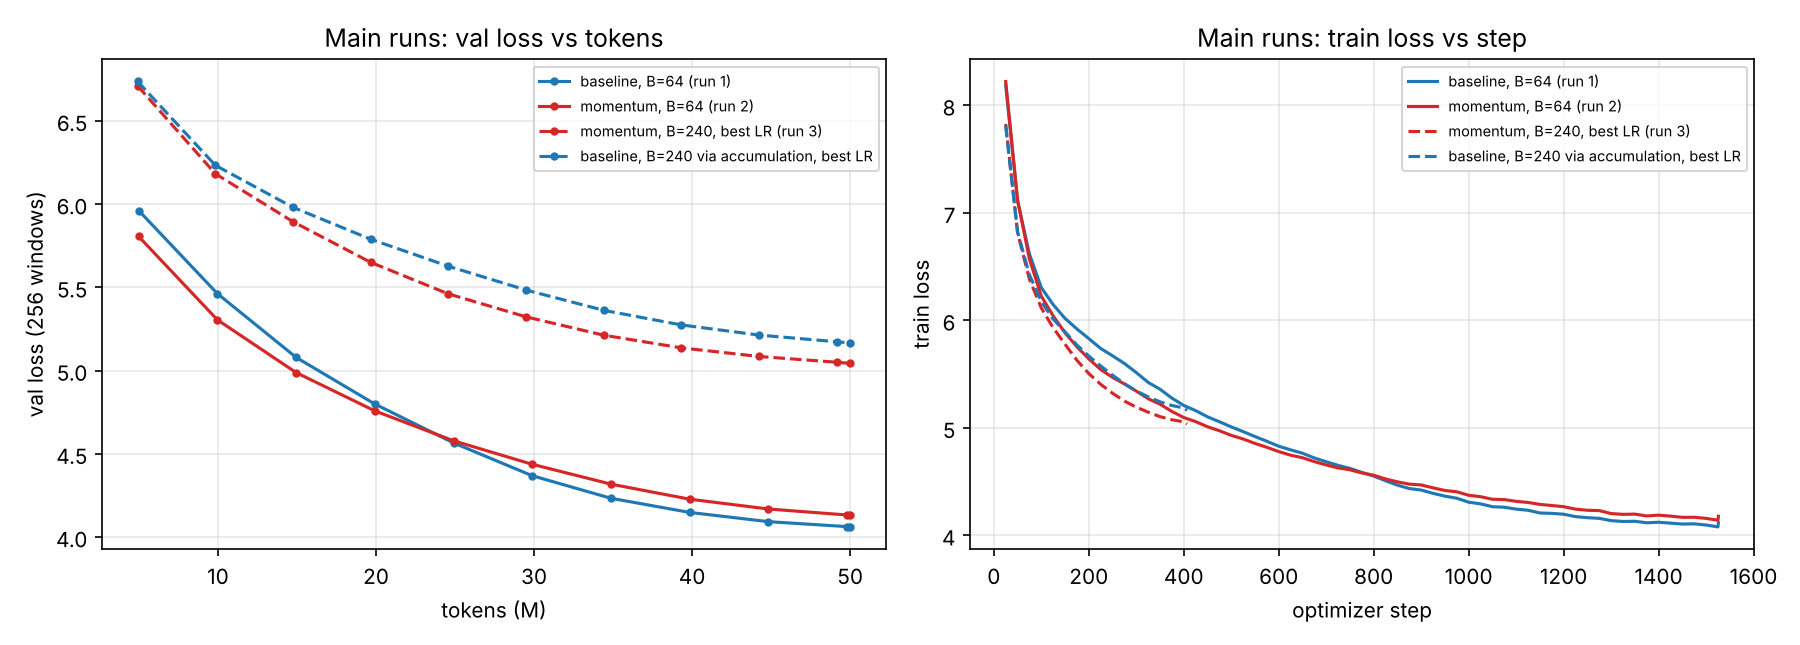

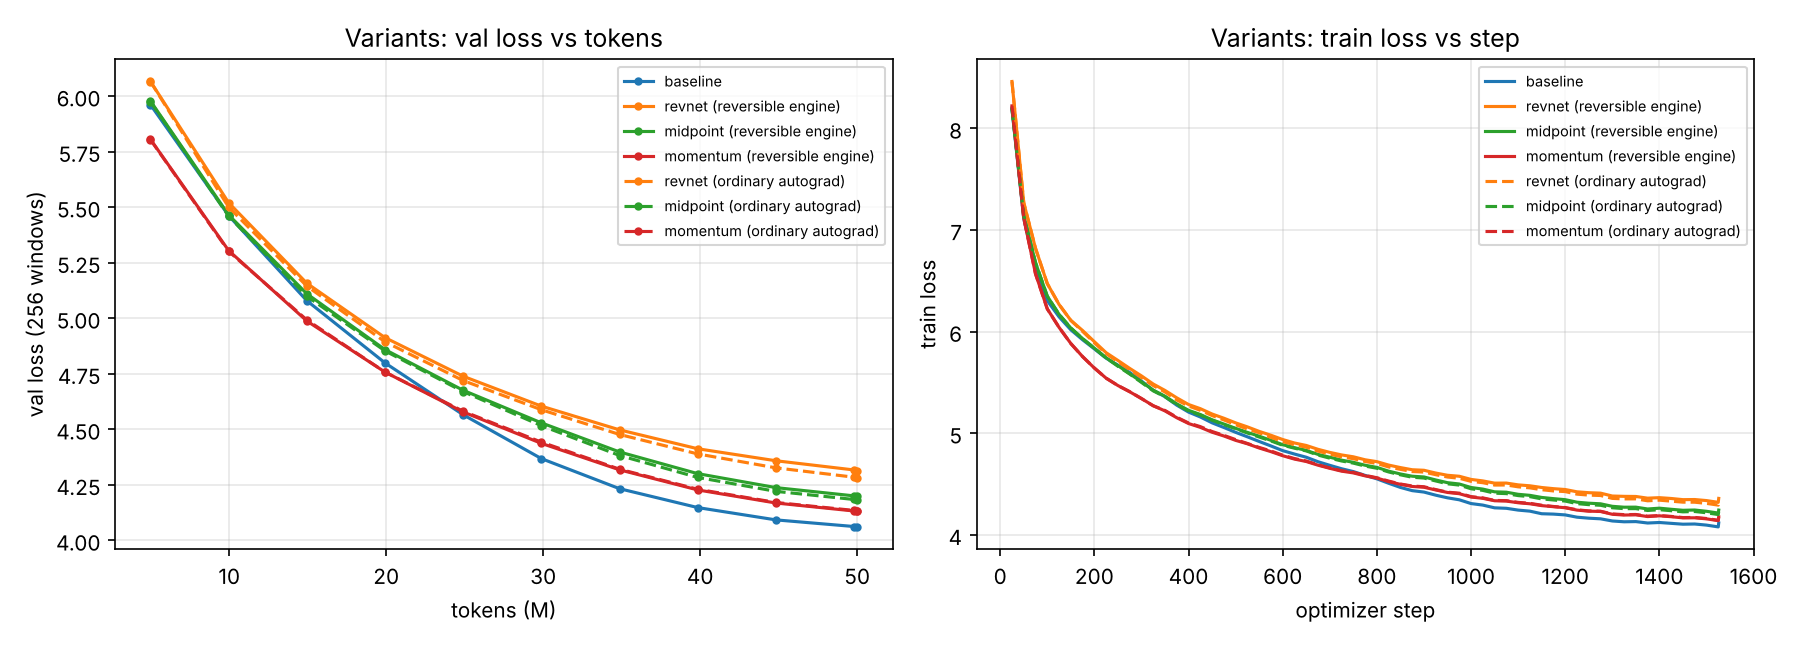

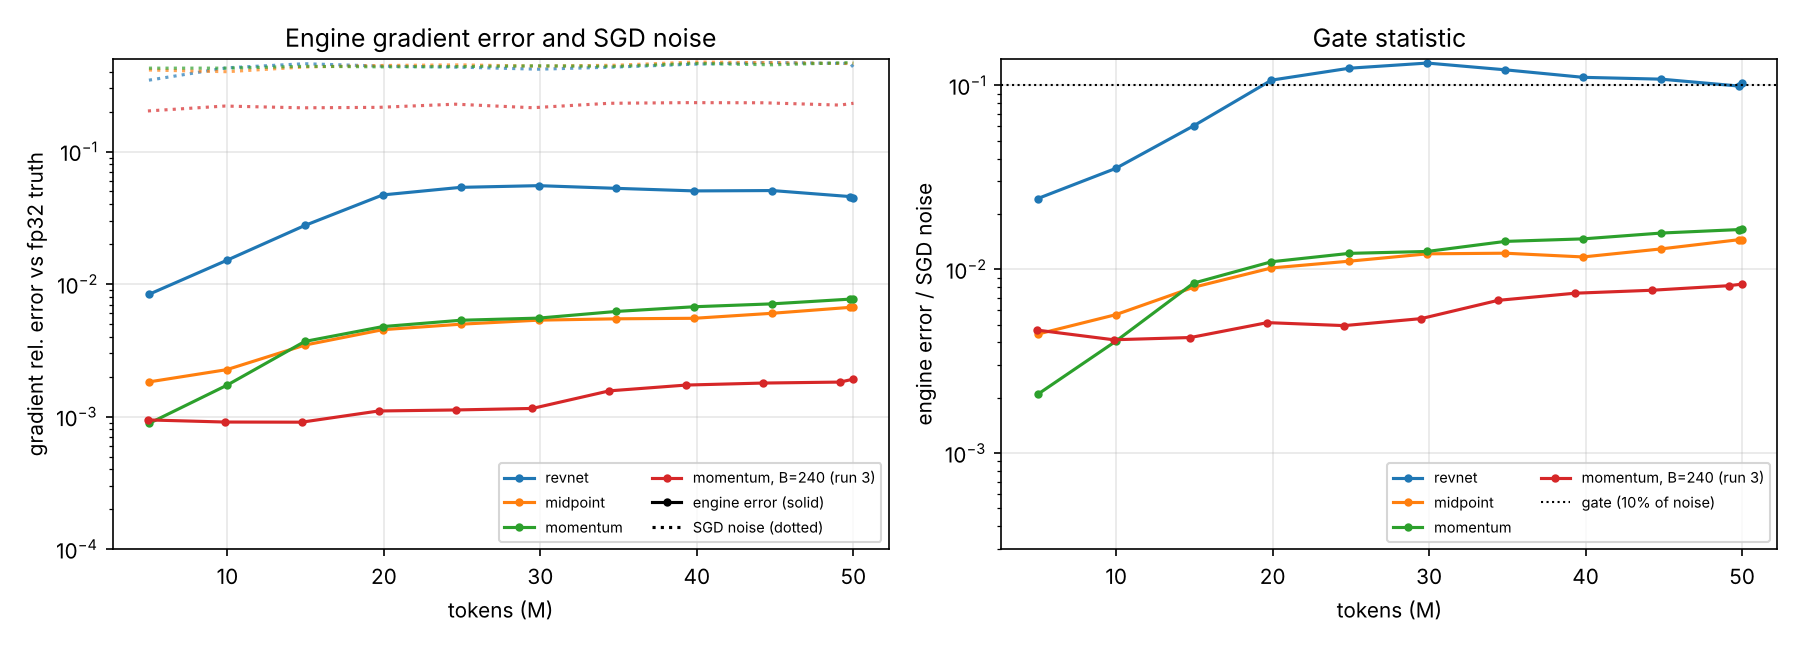

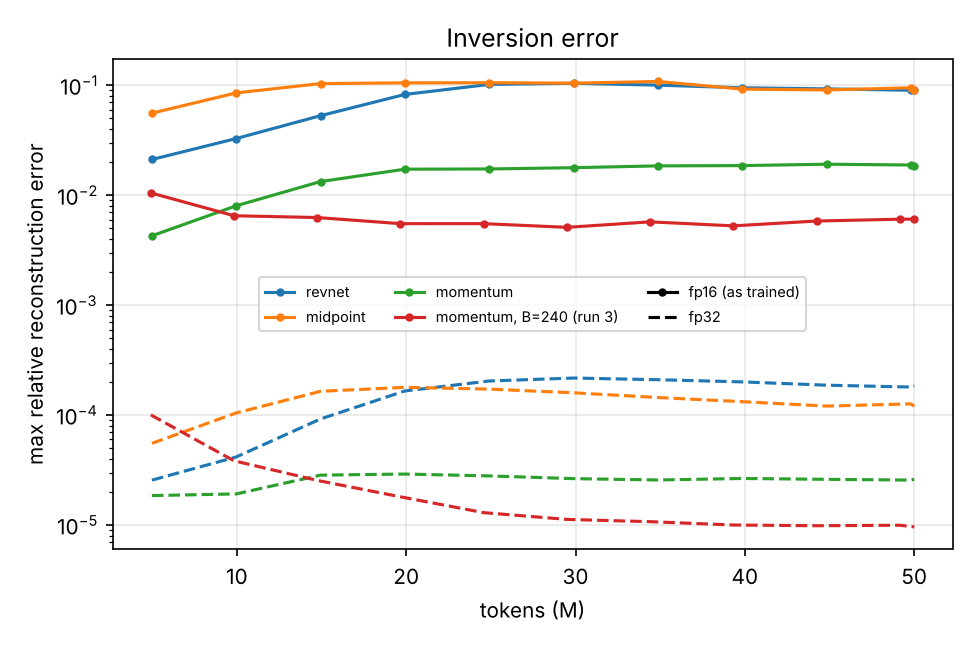

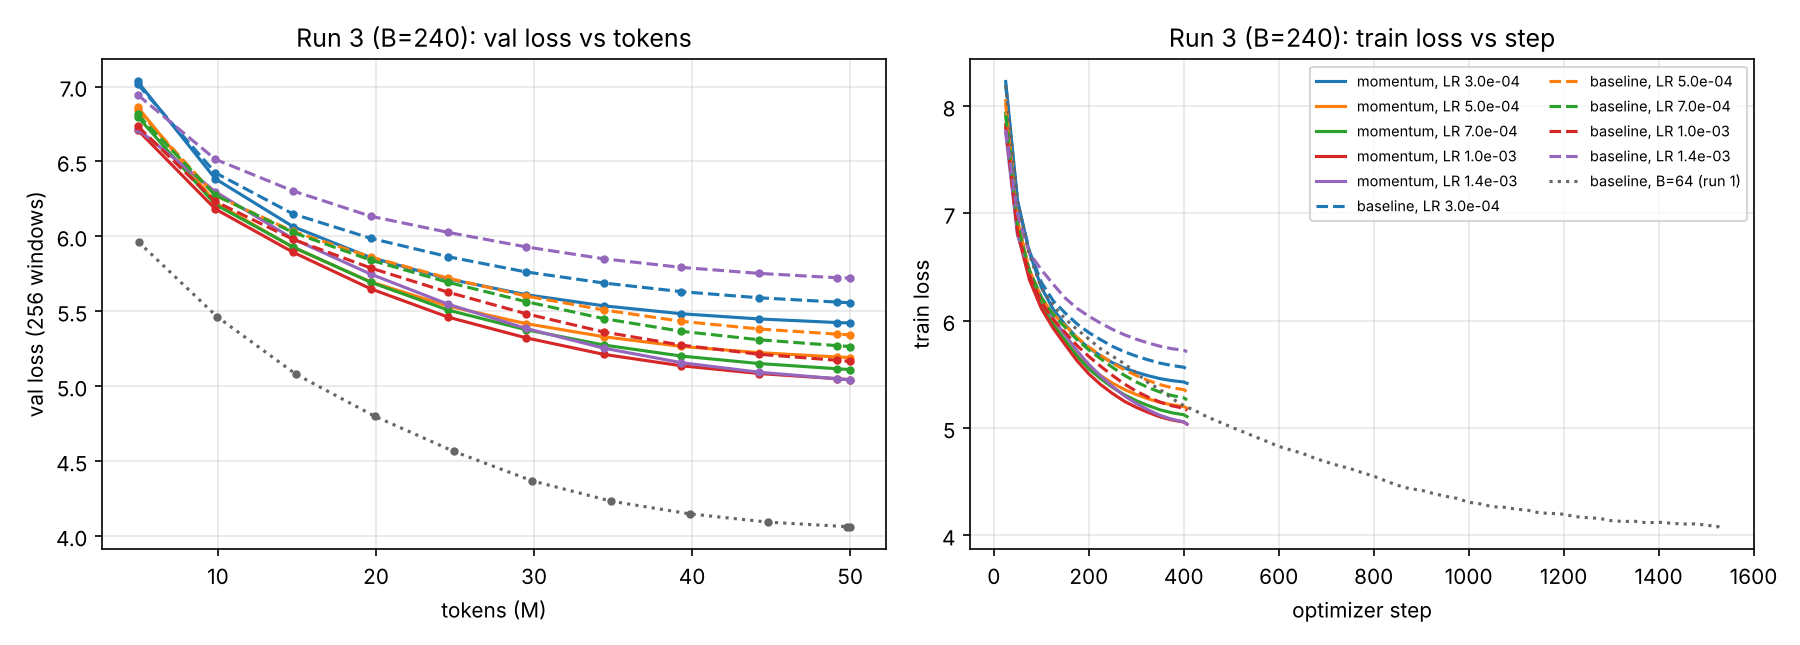

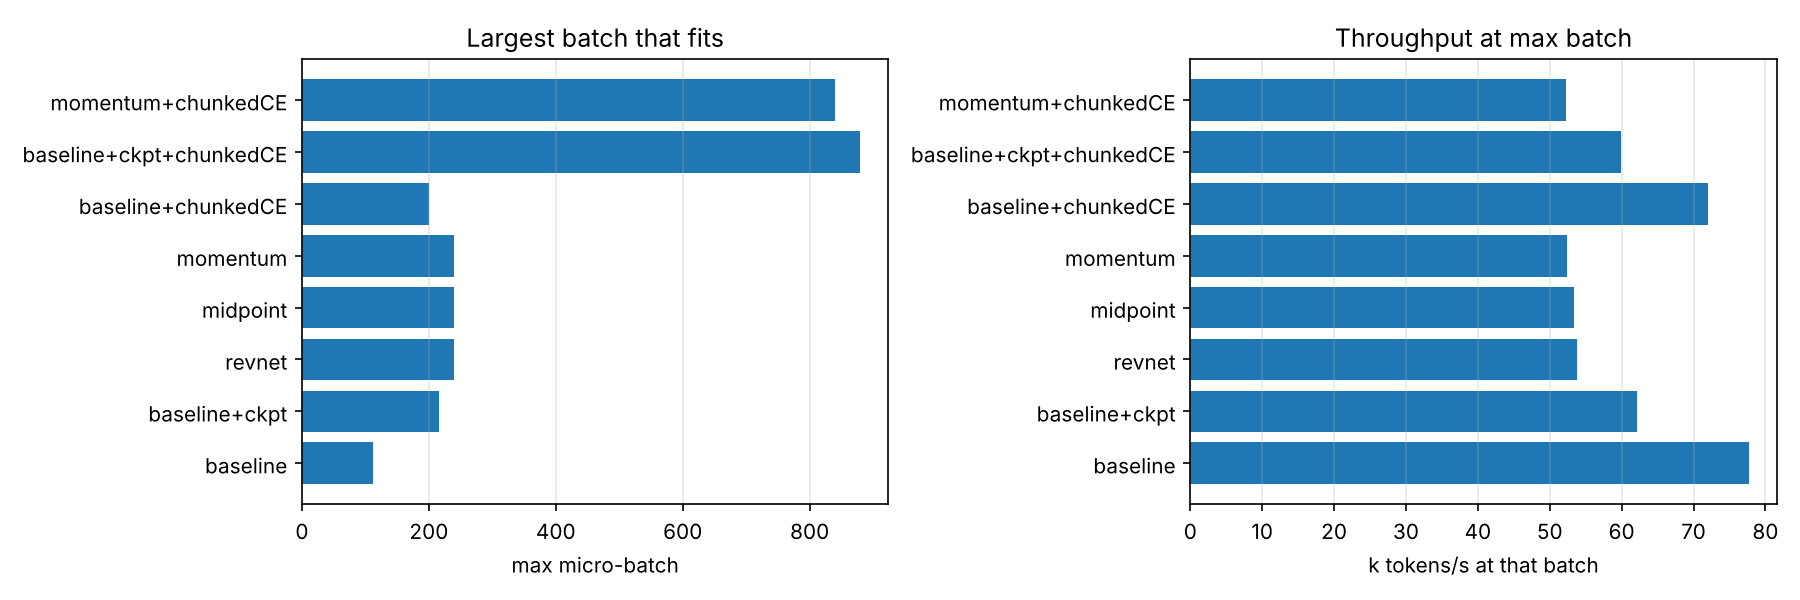

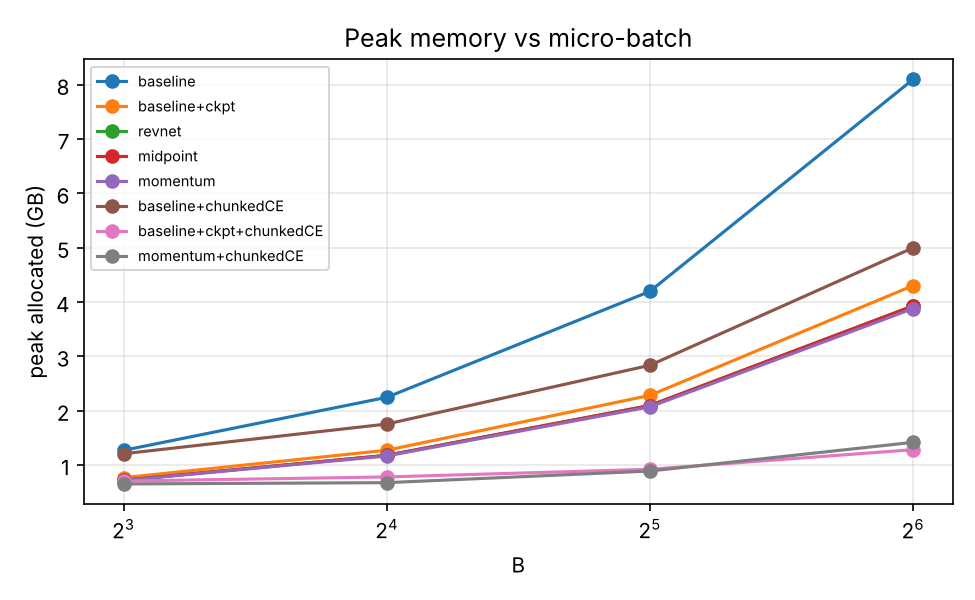

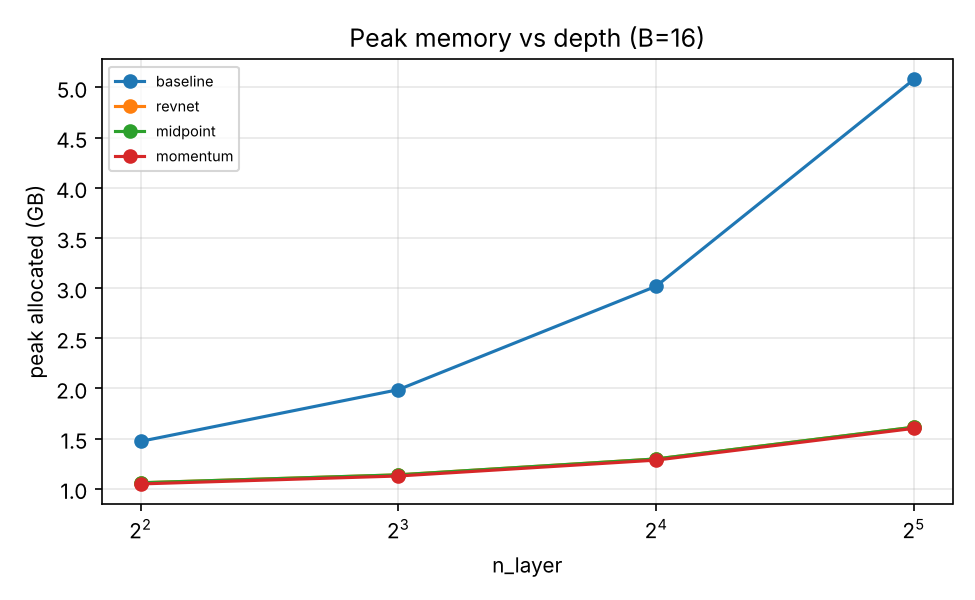

In [25]:
res = load_results(RES_DIR)
main = ["run1_baseline", f"run2_{winner}", run3]
_acc = res[accum_name]["train_cfg"]

# Main runs: colour = architecture, dashed = trained at the max batch (run 3 and its baseline control).
main_styles = {"run1_baseline": dict(color="C0", label=f"baseline, B={B_BASE} (run 1)"),
               f"run2_{winner}": dict(color="C3", label=f"{winner}, B={B_BASE} (run 2)"),
               run3: dict(color="C3", ls="--", label=f"{winner}, B={B_MAX}, best LR (run 3)"),
               accum_name: dict(color="C0", ls="--",
                                label=f"baseline, B={_acc['micro_batch'] * _acc['grad_accum']} via accumulation, best LR")}
plot_loss_curves(res, main + [accum_name], f"{ASSETS}/loss_main.png", "Main runs:", main_styles)

# Variants: colour = architecture, solid = reversible engine, dashed = same architecture with ordinary autograd.
arch_col = {"baseline": "C0", "revnet": "C1", "midpoint": "C2", "momentum": "C3"}
var_styles = {"run1_baseline": dict(color="C0", label="baseline")}
for v in VARIANTS:
    var_styles[f"run2_{v}"] = dict(color=arch_col[v], label=f"{v} (reversible engine)")
    var_styles[controls[v]] = dict(color=arch_col[v], ls="--", label=f"{v} (ordinary autograd)")
plot_loss_curves(res, ["run1_baseline"] + variant_runs + gamma_runs + list(controls.values()),
                 f"{ASSETS}/loss_variants.png", "Variants:", var_styles)

# Run 3: colour = peak LR, solid = reversible, dashed = baseline at the same effective batch and LR.
_lrs = sorted({res[n]["train_cfg"]["lr"] for n in sweep + accum_sweep if n in res})
lr_col = {lr: f"C{i % 10}" for i, lr in enumerate(_lrs)}
r3_styles = {"run1_baseline": dict(color="0.4", ls=":", label=f"baseline, B={B_BASE} (run 1)")}
for n in sweep:
    lr = res[n]["train_cfg"]["lr"]; r3_styles[n] = dict(color=lr_col[lr], label=f"{winner}, LR {_lr(lr)}")
for n in accum_sweep:
    lr = res[n]["train_cfg"]["lr"]; r3_styles[n] = dict(color=lr_col[lr], ls="--", label=f"baseline, LR {_lr(lr)}")
plot_loss_curves(res, sweep + accum_sweep + ["run1_baseline"], f"{ASSETS}/loss_run3.png", f"Run 3 (B={B_MAX}):",
                 r3_styles, legend="right", ncol=2)

plot_audit(res, variant_runs + gamma_runs + [run3], f"{ASSETS}/grad_audit.png")
plot_recon(res, variant_runs + [run3], f"{ASSETS}/recon_error.png")
plot_maxbatch(mb_rows, f"{ASSETS}/max_batch.png")
plot_probe(mbp, "B", "config", f"{ASSETS}/mem_vs_batch.png", "Peak memory vs micro-batch")
plot_probe(depth_rows, "n_layer", "arch", f"{ASSETS}/mem_vs_depth.png", "Peak memory vs depth (B=16)")
for f in ["loss_main", "loss_variants", "grad_audit", "recon_error", "loss_run3", "max_batch", "mem_vs_batch", "mem_vs_depth"]:
    display(Image(f"{ASSETS}/{f}.png"))

In [26]:
README_TEMPLATE = r'''# Reversible GPT: trading compute for memory in a 21M-parameter LLM

A ~21M-parameter GPT trained on a 50M-token FineWeb-Edu budget, with and without reversible residual blocks, on one Colab T4.

| Run | What | Question it answers |
|---|---|---|
| 1. Baseline | Standard pre-norm GPT, micro-batch `B_BASE` | Reference loss, speed, memory |
| 2. Reversible | RevNet (symplectic Euler), leapfrog midpoint and momentum, **each on the full budget** at `B_BASE`; the best that passes a numerics gate is selected | What does reversibility cost and save at equal batch, and which variant works? |
| 3. Reversible, max batch | Selected variant at its largest micro-batch, with an LR sweep and a same-effective-batch baseline control | What does the saved memory buy? |

Supporting experiments: a seed study (3 seeds for runs 1 and 2); for **every** variant, the same architecture trained with ordinary autograd, which separates "reversible architecture" from "reversible backward"; a baseline at run 3's effective batch, LR-tuned over the same grid; a max-batch vs max-batch table including activation checkpointing; and memory probes with and without a chunked loss.

Every number in this README is generated from `results/*.json` by the notebook. Nothing is typed by hand.

## Answer to the brief

<!-- BRIEF:START -->
_Filled automatically by the notebook._
<!-- BRIEF:END -->

---

## 1. Setup

| Item | Value |
|---|---|
| Data | FineWeb-Edu `sample-10BT`, streamed. Training budget: at least 50M tokens per run (step count rounded up, so a run trains 50.00–50.01M tokens; the exact count is in the results table). No token is seen twice. |
| Validation | 1,500 held-out documents = 1M tokens. **Final** val losses use all 1M; the curves during training use the first 256 windows (131k tokens). |
| Tokenizer | Byte-level BPE, 8,192 tokens, trained on 20k documents that exclude the validation documents |
| Model | 10 layers, d=384, 6 heads, context 512, MLP 4x, GELU, LayerNorm (no bias), learned positions, tied embeddings: 21.05M parameters (17.70M non-embedding) |
| Optimizer | AdamW (0.9, 0.95), weight decay 0.1 on matrices, clip 1.0, peak LR 1e-3, warmup max(5% of steps, 25), cosine to 10% |
| Precision | fp16 autocast + GradScaler on T4 (bf16 on Ampere+); residual stream always fp32 |
| Seeds | 1337 for every run; seeds 1338 and 1339 added for runs 1 and 2. A seed fixes both initialisation and data order. |

**Why an 8k vocabulary.** With GPT-2's 50k vocabulary, ~19M of 21M parameters would be embedding, and the logits tensor would dominate activation memory. Reversibility only removes *block* activations, so a huge head would hide the effect being measured. Even at 8k the head turns out to be the largest memory consumer (section 5).

**Fairness controls.** All architectures have identical parameter tensors, created in the same order, so a given seed gives identical initial weights. Data is cut into non-overlapping 513-token windows in one seeded order; any batch size consumes the same windows in the same order. Throughput excludes the first 5% of steps and all evaluation. Peak memory is `torch.cuda.max_memory_allocated` over the whole run.

---

## 2. Reversibility and the three variants

A standard residual block, `x_{n+1} = x_n + F(x_n)`, is forward Euler on `dx/dt = F(x)` and cannot be inverted in closed form, so backprop stores every layer's activations. A reversible scheme can be undone exactly; the backward pass rebuilds each layer's input from its output, so only the final state is stored. The price is one extra forward per layer: ≈ +33% FLOPs.

With `F` = attention sublayer, `G` = MLP sublayer and `D(x) = F(x) + G(x + F(x))` the whole block's update:

| Variant | ODE view | Forward step | Exact inverse | Float-error behaviour |
|---|---|---|---|---|
| `revnet` | Symplectic Euler on a split state | `y1 = x1 + F(x2)`, `y2 = x2 + G(y1)` | `x2 = y2 − G(y1)`, `x1 = y1 − F(x2)` | Rounding × layer Jacobians |
| `midpoint` | Leapfrog / explicit midpoint | `x_{n+1} = x_{n−1} + D(x_n)` | `x_{n−1} = x_{n+1} − D(x_n)` | Rounding × layer Jacobians |
| `momentum` | Momentum ResNet (Sander et al. 2021) | `v' = γv + (1−γ)·D(x)`, `x' = x + v'` | `x = x' − v'`, `v = (v' − (1−γ)·D(x))/γ` | Additionally ×1/γ per layer |

Each scheme's backward step evaluates every sublayer once, reusing the same evaluation for reconstruction and gradient. The residual stream is fp32 throughout.

---

## 3. What changed after the first GPU run, and why

The first full run (v1) exposed four design problems. Its numbers are kept here for transparency.

| v1 result | Diagnosis | v2 change |
|---|---|---|
| Momentum used `v' = γv + D(x)` (α = 1). Trained-model gradient error vs autograd 0.35 (min cosine 0.94); reconstruction error 2.0 (200%). | Unnormalised velocity accumulates up to 1/(1−γ) = 10 block updates, over-weighting early layers and making the inverse ill-conditioned. | α = 1 − γ (Sander et al.'s normalisation). |
| Variant chosen from 10M-token pilots on a compressed schedule: momentum 5.82 vs revnet 5.98, midpoint 5.96, baseline 5.99. | At loss ≈ 6 the ranking measured early speed, not final quality. The compressed cosine also hurt: the pilot baseline reached 5.99 at 10M tokens; the full-schedule baseline had 5.45 at the same 10M tokens. Both are the same model and data; the gap is the LR decaying while the loss is still high. | No pilots: every variant trains on the full budget and schedule. Selection requires passing a numerics gate during training. |
| Run 3 (momentum, B=240, LR 1.94e-3): val 5.82 vs 4.10 for the baseline. | The baseline was at 5.19 after the same 406 optimizer steps, so ~1.1 nats of the gap is expected from step count alone; run 3's curve has the same shape as the compressed-schedule pilots. The remaining ~0.6 nats could not be attributed: no control, no LR sweep, and momentum's numerics had failed. | LR sweep at the max batch; a baseline at the same effective batch via gradient accumulation; a per-step health check in the findings. |
| "3.75x batch" headline. | The baseline's own search fit B=112, so the real max-vs-max gain was 2.14x. Checkpointing reached 4.30 GB vs 3.87 GB at B=64, within about 10% of reversible. | Max-batch vs max-batch table for baseline, checkpointing and all variants, with and without a chunked loss. |

Smaller corrections: trained-token counts are stated exactly; the val set size used for each number is stated; the fp64 exactness test now runs in the notebook and is saved to `correctness.json`; gradient checks now compare against an fp32 ground truth instead of against mixed-precision autograd.

### v2 → v3

The v2 run (score 80/100) exposed measurement and inference problems rather than model problems.

| v2 issue | Evidence | v3 change |
|---|---|---|
| Tokens/s inflated | An eval landing between two log points reset the segment timer but not its token count, so that segment's tokens were divided by too little time. | The partial segment is flushed (time and tokens) before every eval. |
| Peak memory could include the audit | `max_memory_allocated` was read after training, so it also covered evaluation and the fp32 gradient audit. | Training peak and eval peak are recorded separately (`peak_mem_alloc_GB` = training only). |
| MFU peak lookup | Substring match: "A10" matched "A100", "L4" matched "L40S". | Whole-name match, longest key first. |
| Run-3 LR optimum on the grid edge | Loss rose with LR: 1e-3 → 5.06, 2e-3 → 5.39, 3e-3 → 5.58. The baseline control was trained only at 1e-3. | Grid 3e-4…1e-3, extended automatically past any edge optimum; the baseline control is tuned over the same grid; reversible-with-autograd at the large batch. |
| Health check compared unlike things | It interpolated a 256-window validation curve against run 3's 1M-token final loss, at a step where the baseline was mid-schedule. | Removed. The comparator is the tuned baseline at the same effective batch. |
| Noisy, arbitrary numerics gate | 2-window (1,024-token) audit; max over 11 audits; "3× the AMP floor" not tied to training. | 16-window audits (computed in chunks); 90th percentile; threshold = 10% of the SGD gradient noise at the training batch size. |
| Engine effect only for the winner | revnet's and midpoint's gaps to the baseline could not be attributed. | Autograd controls for all three variants. |
| Error bars mislabelled | Group "±" values were standard deviations; the engine effect "+0.0002" was a single pair quoted to 4 decimals. | mean ± SE (n, sd); single differences are judged against the run-to-run sd (≈ 0.007 in v2). |

---

## 4. Rules and hypotheses

**Hypotheses H1–H5 were specified before the v2 runs**, and are kept unchanged so they can be scored. **The v3 numerics gate was specified after seeing the v2 results**, so it is not pre-registered; the v2 ("legacy") gate is still computed, and the findings say if the two gates would select different variants.

**Numerics gate (v3).** At every evaluation, a gradient audit compares the mixed-precision reversible engine with an fp32 autograd ground truth on the same weights, over 16 validation windows. The scale that matters for training is the SGD gradient noise: two disjoint 16-window batches give ‖g_A − g_B‖, rescaled to the training batch size B as ‖g_A − g_B‖·√(16 / 2B). A variant passes if, at the 90th percentile over its audits, engine error ≤ 10% of that noise and cosine to the truth ≥ 0.99. Mixed-precision autograd's own error ("AMP floor") is reported alongside as a reference.

**Legacy gate (v2).** Engine error ≤ 3× the AMP floor and cosine ≥ 0.99 at every audit.

**Selection.** The lowest final val loss among variants passing the v3 gate.

**Significance.** A difference between seed means counts only if it exceeds 2 standard errors. A single paired difference (engine − autograd) is judged against the run-to-run sd: below 1 sd it is called indistinguishable from seed noise.

Hypotheses (as written before v2):

1. `revnet` and `midpoint` pass the gate; `momentum` is the most fragile, from the 1/γ factor.
2. For a gated variant, the engine effect on loss (engine − autograd, same architecture) is within seed noise.
3. Run 3 lands within 0.05 of the same-effective-batch baseline: the large-batch penalty is fewer steps, not reversibility.
4. With a full logits tensor, reversibility beats checkpointing on max batch by under 15%; with a chunked loss, by over 1.5x.
5. At equal batch, peak memory falls about 50% and throughput 25–35%.

---

## 5. Results

### Main runs

<!-- RESULTS:START -->
_Filled automatically by the notebook._
<!-- RESULTS:END -->

### Variants on the full budget

<!-- VARIANTS:START -->
_Filled automatically by the notebook._
<!-- VARIANTS:END -->

### Run 3: LR sweep at the max batch, reversible vs baseline

Both at the same effective batch and token budget; the baseline uses gradient accumulation. Final val loss on the full 1M-token validation set.

<!-- RUN3:START -->
_Filled automatically by the notebook._
<!-- RUN3:END -->

### Max batch vs max batch

<!-- MAXBATCH:START -->
_Filled automatically by the notebook._
<!-- MAXBATCH:END -->

### Hypothesis scorecard (computed)

<!-- SCORECARD:START -->
_Filled automatically by the notebook._
<!-- SCORECARD:END -->

### Findings (computed from the JSON files)

<!-- FINDINGS:START -->
_Filled automatically by the notebook._
<!-- FINDINGS:END -->

### Where the memory goes

The memory-vs-batch slope is activation memory per token. The intercept is weights, grads and AdamW states. `+chunkedCE` computes the LM head and loss in checkpointed chunks, so the B·T·V logits tensor never exists.

<!-- PROBES:START -->
_Filled automatically by the notebook._
<!-- PROBES:END -->

![main runs](assets/loss_main.png)
![variants](assets/loss_variants.png)
![gradient audit](assets/grad_audit.png)
![reconstruction](assets/recon_error.png)
![run 3](assets/loss_run3.png)
![max batch](assets/max_batch.png)
![memory vs batch](assets/mem_vs_batch.png)
![memory vs depth](assets/mem_vs_depth.png)

---

## 6. Reproduce

One notebook, `rev_gpt.ipynb`, contains all the code. In Colab: Runtime → Change runtime type → **T4 GPU**, then Runtime → **Run all**.

| Setting | `BUDGET = "full"` (default) | `BUDGET = "core"` |
|---|---|---|
| Runs | baseline; 3 variants + 3 autograd controls; 2 extra seeds each for runs 1 and 2; 4-LR sweep at max batch for reversible and baseline (auto-extended past an edge optimum); autograd control at max batch | baseline; 3 variants + 3 autograd controls; one LR (1e-3) at max batch for reversible and baseline |
| Training runs | 20 (+ up to 4 extension runs) | 9 |
| Approx. T4 time | ~5 h | ~2.3 h |

Use `USE_DRIVE = True` for the full budget: results then live in `MyDrive/rev-gpt/`, and Run all after a disconnect resumes from the first unfinished run. Without Drive, a disconnect loses the session's files.

## 7. Repository

```
rev_gpt.ipynb   code cells [0]-[10], then the experiment steps, executed with outputs
README.md                  this file (results sections filled by the notebook)
results/*.json             one file per run: curves, metrics, gradient audits
assets/*.png               figures used above
```

## 8. Limitations

- Three seeds give a rough error bar, not a precise one.
- The LR sweeps at max batch pick their best LR on the validation set, so both best losses are slightly optimistic; since reversible and baseline are tuned the same way, the comparison between them is fair.
- Single paired differences (engine − autograd) have no error bar of their own; they are judged against the seed-to-seed spread, estimated from 3 seeds.
- The v3 numerics gate was designed after the v2 results (see section 4).
- `torch.compile` is off for every run; the custom backward calls autograd inside autograd. Absolute tokens/s is below what a compiled baseline would reach.
- Training uses the full logits tensor; the chunked loss is measured in probes only.
- Only γ = 0.9 is trained for momentum; `GAMMA_SWEEP = True` adds γ = 0.5 and 0.7.

## References

- Gomez, Ren, Urtasun, Grosse (2017). *The Reversible Residual Network.* NeurIPS.
- Chang, Meng, Haber et al. (2018). *Reversible Architectures for Arbitrarily Deep Residual Neural Networks.* AAAI.
- Sander, Ablin, Blondel, Peyré (2021). *Momentum Residual Neural Networks.* ICML.
- Kitaev, Kaiser, Levskaya (2020). *Reformer: The Efficient Transformer.* ICLR.
- Mangalam et al. (2022). *Reversible Vision Transformers.* CVPR.
- Chowdhery et al. (2022). *PaLM*, Appendix B (FLOPs and MFU accounting).
'''

In [27]:
ctx = {"winner": winner, "variants_short": VARIANTS, "controls": controls, "seeds": seed_runs,
       "run3_sweep": sweep, "ctrl_accum_sweep": accum_sweep, "ctrl3_autograd": ctrl3_autograd,
       "maxbatch": mb_rows, "fits": fits, "B_BASE": B_BASE, "selection_note": selection["note"]}
seed_names = [n for k in seed_runs for n in seed_runs[k] if n not in main]
sections = {
    "BRIEF": brief_answer_md(res, ctx),
    "RESULTS": results_table_md(res, main + [accum_name] + ([ctrl3_autograd] if ctrl3_autograd else []) + seed_names),
    "VARIANTS": variant_table_md(res, VARIANTS, controls),
    "RUN3": run3_table_md(res, sweep, accum_sweep),
    "MAXBATCH": maxbatch_table_md(mb_rows),
    "SCORECARD": scorecard_md(res, ctx),
    "FINDINGS": findings_md(res, ctx),
    "PROBES": probe_md(fits, depth_rows),
}
README = f"{ROOT}/README.md"
with open(README, "w") as fh:
    fh.write(README_TEMPLATE)
update_readme(README, sections)
for k in ("BRIEF", "SCORECARD", "FINDINGS"):
    display(Markdown(sections[k]))

**Variant that worked:** `momentum`: the lowest final loss among variants whose gradient error stayed below 10% of SGD noise (p90 0.016); failed the gate: `revnet`. **At the same micro-batch (64):** peak training memory 3.88 GB vs 8.10 GB (-52%), throughput 55,484 vs 77,634 tokens/s (-29%). Final val loss is +0.058 ± 0.006 (SE, n=3 seeds per arm) vs the baseline. The reversible backward itself changes the loss by -0.004 (same architecture trained with ordinary autograd), so the gap is the `momentum` architecture, not the memory-saving engine. **Max batch:** `momentum` fits 240 vs the baseline's own maximum 112 (2.14x). Trained there on the same tokens (best LR 1.0e-03), it runs at 52,583 tokens/s (-5% vs B=64) and reaches 5.0555, vs 5.1800 for the baseline at the same effective batch, tuned over the same LR grid (-0.124). The larger batch itself costs +1.078 vs run 1, because the same tokens buy 3.75x fewer optimizer steps. **Bottom line:** activation checkpointing fits 90% of the reversible max batch at 19% higher throughput (62,092 vs 52,386 tokens/s), with exact gradients and no architecture change. With the logits tensor removed (chunked loss), checkpointing still fits at least as much (880 vs 840). At this depth, checkpointing is the better tool.


| # | Hypothesis | Measured | Verdict |
|---|---|---|---|
| H1 | revnet and midpoint pass the gate; momentum is the most fragile | v2 gate (as written): revnet FAIL, midpoint FAIL, momentum FAIL. v3 gate: revnet FAIL, midpoint pass, momentum pass. Most fragile (largest p90 engine error / SGD noise): `revnet` | not supported |
| H2 | engine effect on loss (engine − autograd) within seed noise | `momentum`: |Δ| < 0.008, indistinguishable from seed noise (run-to-run sd ≈ 0.007) | supported |
| H3 | run 3 within 0.05 of the baseline at the same effective batch | -0.1244, each at its best LR; reversible better at 5 of 5 shared LRs | not supported: reversible better |
| H4 | vs checkpointing: < 1.15x max batch with full logits, > 1.5x with chunked loss | full logits: 1.11x checkpointing; chunked loss: 0.95x | half true |
| H5 | equal batch: peak memory ≈ −50% (−40..−60), throughput −25..−35% | memory -52.1%, throughput -28.5% | supported |


- **Variant selection (all on the full budget):** `revnet` 4.3516 (v3 gate FAIL, p90 engine/noise 0.12); `midpoint` 4.2409 (v3 gate pass, p90 engine/noise 0.014); `momentum` 4.1718 (v3 gate pass, p90 engine/noise 0.016). Selected: **`momentum`**. Note: no variant passes the legacy v2 gate (engine error <= 3x the AMP floor at every audit; worst ratios `revnet` 57.3x, `midpoint` 5.3x, `momentum` 5.1x), so it cannot select a variant.
- **Same batch (64):** peak training memory -52.1%, throughput -28.5%; baseline 4.1080 ± 0.0047 SE (n=3, sd 0.0082); `momentum` 4.1661 ± 0.0035 SE (n=3, sd 0.0061); gap +0.0581 ± 0.0059 SE, a real difference.
- **Engine vs architecture, `revnet`:** engine − autograd: +0.031, larger than seed noise (2-sigma band for one pair ±0.020). Architecture effect (autograd `revnet` − baseline): +0.219.
- **Engine vs architecture, `midpoint`:** engine − autograd: +0.015, within seed noise (2-sigma band for one pair ±0.020). Architecture effect (autograd `midpoint` − baseline): +0.124.
- **Engine vs architecture, `momentum`:** engine − autograd: |Δ| < 0.008, indistinguishable from seed noise (run-to-run sd ≈ 0.007). Architecture effect (autograd `momentum` − baseline): +0.074.
- **Numerics (`momentum`, trained):** gradient error 7.66e-03 vs SGD noise 4.65e-01 at the training batch (p90 ratio 0.016); mixed-precision autograd alone 1.90e-03 (p90 engine/floor 5.00x). Reconstruction error 1.85e-02 under AMP vs 2.61e-05 in fp32.
- **Max batch vs max batch:** baseline 112, `momentum` 240 (2.14x); tokens/s at max 77,689 vs 52,386. Checkpointing: 216 at 62,092 tokens/s (reversible = 1.11x its batch, -16% its throughput).
- **Logits floor removed (chunked loss):** max batch baseline 200, checkpointing 880, `momentum` 840 (0.95x checkpointing).
- **Where the memory goes:** activation cost 250 KB/token (baseline), 129 (checkpointing), 116 (`momentum`). Chunking the loss removes 87 KB/token (75% of `momentum`'s): the LM head is the floor. Without it: checkpointing 21 vs `momentum` 29 KB/token.
- **Run 3 (`momentum`, B=240, 407 steps, 3.75x fewer than run 2):** best LR 1.0e-03 → 5.0555 (flat optimum: the edge LR 1.4e-03 is within 0.0001 of the best, so the true optimum may lie at or beyond 1.4e-03); throughput 52,583 tokens/s (-5.2% vs B=64). Baseline at the same effective batch, tuned over the same grid: best LR 1.0e-03 → 5.1800. Reversible − baseline, best vs best: -0.124, larger than seed noise (2-sigma band for one pair ±0.020); reversible is better at 5 of 5 shared LRs. Cost of the larger batch itself (baseline control − run 1): +1.078. At LR 1.0e-03: engine − autograd |Δ| < 0.008, indistinguishable from seed noise (run-to-run sd ≈ 0.007); architecture (autograd − baseline) -0.122.


### Note on the reporting cells

The run itself is untouched: every training cell above shows its original Colab output. After the run, the reporting code in cell **[10]** was corrected and the cells that only *render* results were re-executed against the saved `results/` files (no model was retrained):

| Cell | What it shows | Why it was re-executed |
|---|---|---|
| Step 5, selection | Which variant was selected, and what the legacy gate concludes | The note claimed the v2 gate "would have selected `midpoint`"; in fact no variant passes it |
| Step 8, plots | The 8 figures | One colour per run across both audit panels; engine/autograd and reversible/baseline pairs share a colour; legends moved off the data |
| Step 8, report | Answer to the brief, scorecard, findings | Checkpointing's throughput edge was inverted (16% → **19%**); a fixed sentence claimed reversibility wins with a chunked loss (the data say 880 vs 840 for checkpointing); H3 gained its direction; the step ratio is 3.75×, not 3.7×; a flat LR optimum is flagged |

Check: re-run with the fixed code, the five data tables of the report (main runs, variants, run-3 sweep, max batch, probes) are byte-identical to those generated on Colab, and so are the tables displayed in Steps 5 to 8. Only the three text sections changed.

---
# Step 9 — Package for GitHub
Zips the README, plots, result JSONs and **this notebook with its outputs** (saved programmatically in Colab; if that fails, use File → Download → .ipynb and add it yourself).

In [ ]:
pkg = "/content/rev-gpt-results" if os.path.isdir("/content") else os.path.abspath("rev-gpt-results")
shutil.rmtree(pkg, ignore_errors=True); os.makedirs(f"{pkg}/results")
shutil.copy(README, pkg); shutil.copytree(ASSETS, f"{pkg}/assets")
for p in glob.glob(f"{RES_DIR}/*.json"):
    shutil.copy(p, f"{pkg}/results/")
with open(f"{pkg}/.gitignore", "w") as fh:
    fh.write("data/\n*.pt\n__pycache__/\n.ipynb_checkpoints/\n")
try:   # Colab can return the live notebook, outputs included
    from google.colab import _message
    nb = _message.blocking_request("get_ipynb", timeout_sec=60)["ipynb"]
    with open(f"{pkg}/rev_gpt.ipynb", "w") as fh:
        json.dump(nb, fh)
    print("notebook with outputs included")
except Exception as e:
    print("could not save the notebook automatically:", repr(e), "-> File > Download > .ipynb")
zip_path = shutil.make_archive(pkg, "zip", pkg)
print("created", zip_path)
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    pass